In [455]:
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import numpy as  np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import scipy.stats as stats
from scipy.stats import shapiro
from scipy.stats import norm

In [456]:
import dashboard as ds
importlib.reload(ds)

<module 'dashboard' from '/media/discoD/Facultad-IS/4to año/Fundamentos de la Ciencia de Datos (copia)/TPE/ciencia-datos-tpe/dashboard.py'>

In [457]:
import utils
importlib.reload(utils)

<module 'utils' from '/media/discoD/Facultad-IS/4to año/Fundamentos de la Ciencia de Datos (copia)/TPE/ciencia-datos-tpe/utils.py'>

In [458]:
data_path = 'results.csv'
df = pd.read_csv(data_path, low_memory=False)

meta_path = 'schema.csv'
metadatos = pd.read_csv(meta_path)

<h1 style="color: orange;">Analisis Exploratorio

<h3 style="color: violet;">Distribucion de variables

El siguiente apartado tiene por objetivo conseguir una primer vista de la distribucion de todas las variables del dataset observando sesgos, posibles outliers, modas, medias, etc.

In [459]:
def maping_and_add(col, values_change, min, dash, multiple=False):
    if not multiple:
        values = df[col].value_counts().index.to_list()
    else:
        values = (
            df[col]
            .dropna()
            .str.split(';')
            .explode()
            .str.strip()
            .value_counts()
        ).index.to_list()
    mapeo = {}
    for i, val in enumerate(values):
        if i == len(values_change): break
        mapeo[val] = values_change[i]
    dash.add.bar(df, col, min=min, cut=mapeo, multiple_r=multiple, max_cat=len(values_change))

<h4><u>Demografía y Perfil Laboral

In [460]:
def histEs(bins=5):
    def draw(ax):
        comp = df['CompTotal'].dropna()
        limite = comp.quantile(0.85)

        comp[comp <= limite].hist(
            bins=bins,
            edgecolor='black',
            ax=ax
        )

        ax.set_title('CompTotal:85%')
        ax.set_xlabel('')
        ax.grid(False)
        ax.tick_params(axis="x", rotation=45)

    return ds.Chart(draw=draw)

In [461]:
dash1 = ds.Dashboard(columns=4, figsize=(20, 4))

In [462]:
maping_and_add('MainBranch', [1, 2, 3, 4, 5, 6], min=2000, dash=dash1)
maping_and_add('EdLevel', ['Bd', 'Md', 'CU', 'Ss', 'Pd', 'Ad', 'Othr', 'Ps'], min=2000, dash=dash1)
maping_and_add('OrgSize', ['20-99', '100-499', '<20', '>10k', '1k-5k', '500-1k', 'Me', '5k-10k', 'DK'], min=2400, dash=dash1)
maping_and_add('DevType', ['Fs', 'Be', 'Stud', 'Arch', 'Fe', 'd_e'], min=2400, dash=dash1)
maping_and_add('RemoteWork', ['Remote', 'H_p', 'Person', 'H_r', 'Choice'], min=2400, dash=dash1)
maping_and_add('NewRole', ['No', 'con_1', 'con_2', 'Yes_v', 'Yes_i'], min=2400, dash=dash1)

In [463]:
df['Employment'] = df['Employment'].replace('Independent contractor, freelancer, or self-employed', 'Independent')
dash1.add.bar(df, "Employment", min=1000, cut=6)

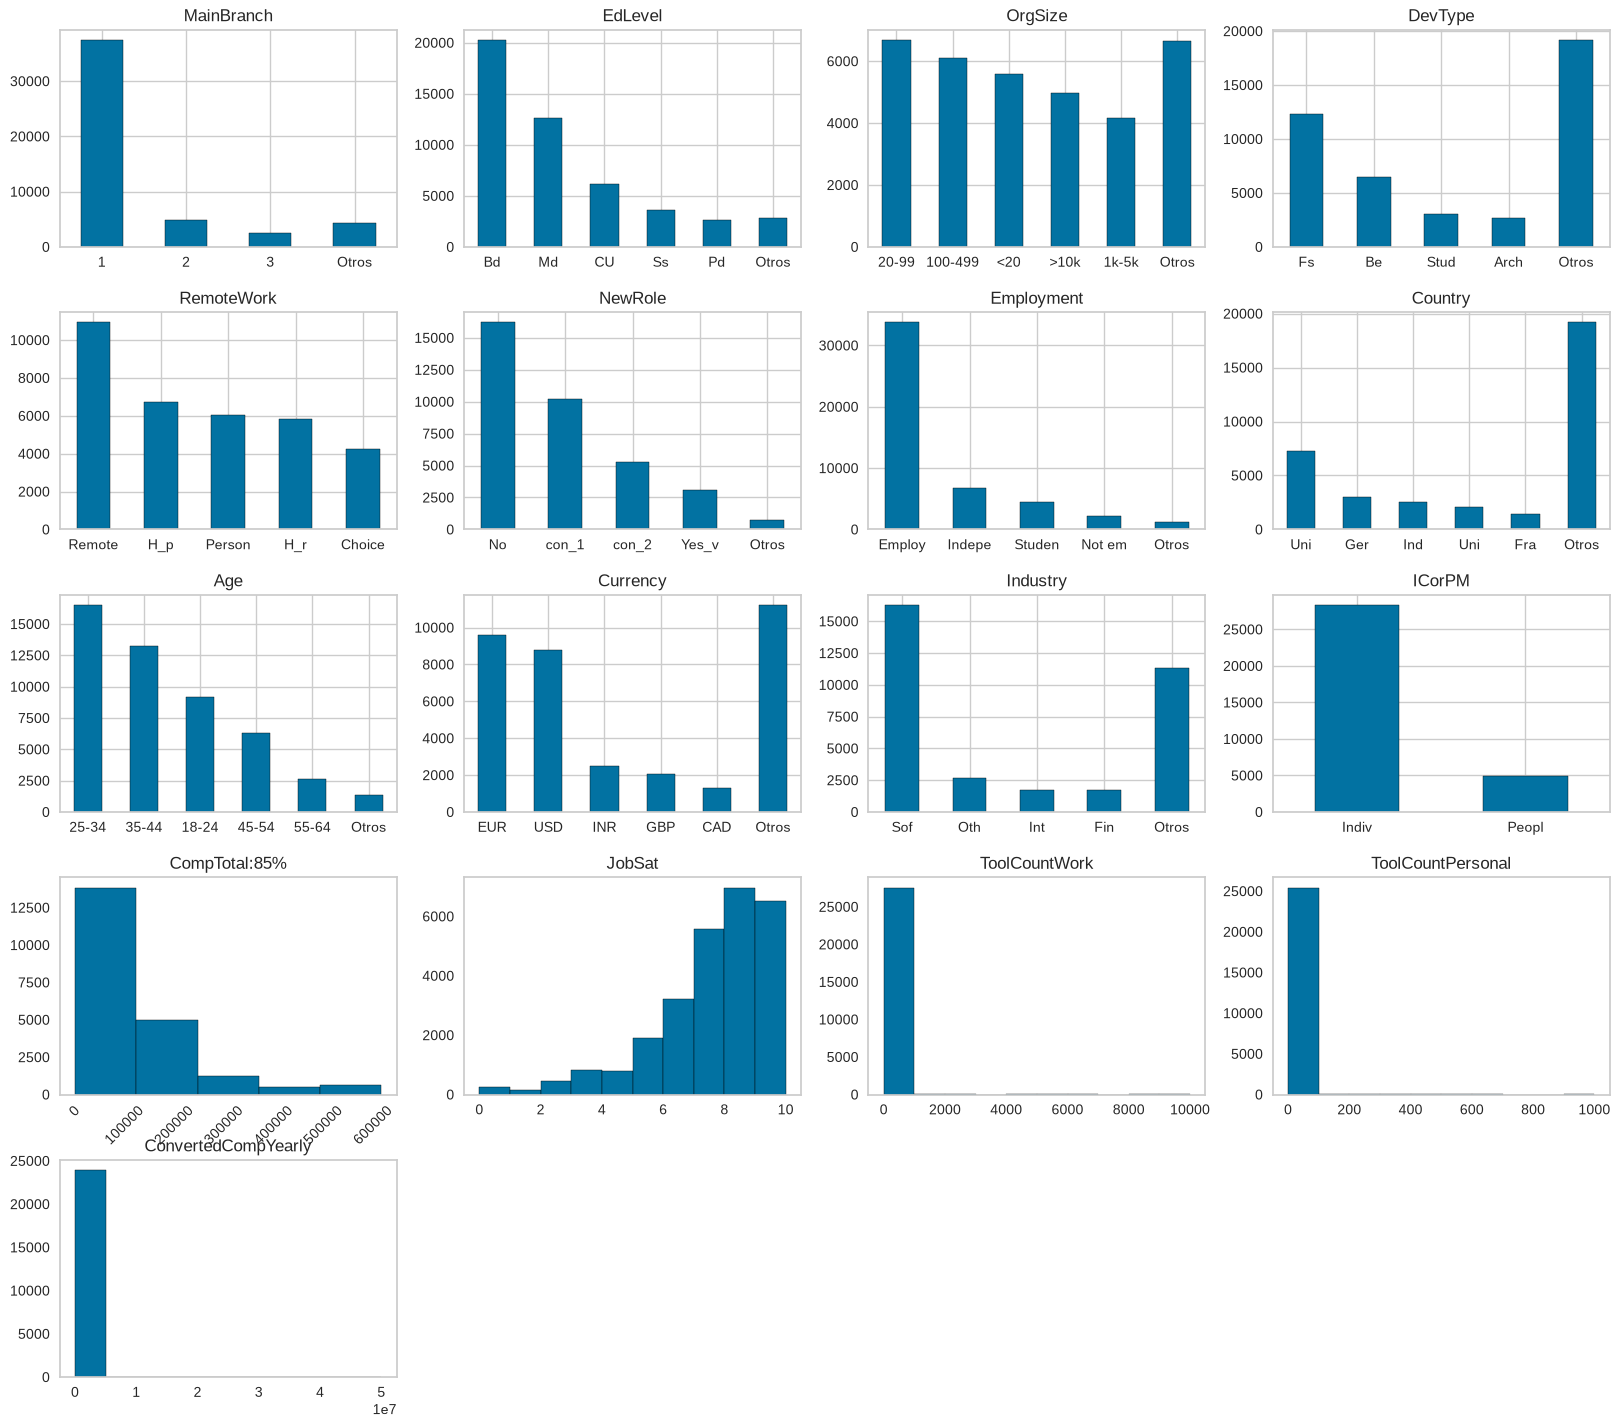

In [464]:
dash1.add.bar(df, "Country", min=1000, cut=3)
dash1.add.bar(df, "Age", min=2000, cut=' ')
dash1.add.bar(df, "Currency", min=1000, cut=3)
dash1.add.bar(df, "Industry", min=1500, cut=3)
dash1.add.bar(df, "ICorPM", min=1500, cut=5)
dash1.addChart(histEs(bins=5))
columnas1 = [
    'MainBranch',
    'Age',
    'Country',
    'Currency',
    'EdLevel',
    'Employment',
    'EmploymentAddl',
    'Industry',
    'OrgSize',
    'DevType',
    'ICorPM',
    'RemoteWork',
    'JobSat',
    'NewRole',
    'ToolCountWork',
    'ToolCountPersonal',
    'ConvertedCompYearly'
]
dash1.add.multiple_hist(df, columnas1, bins=10)

dash1.show()

En el informe estaremos analizando `ToolCountWork`, `ToolCountPersonal`, `ConvertedCompYearly`, `CompTotal` y `JobSat`.

Ampliamos un poco mas en dichas variables 

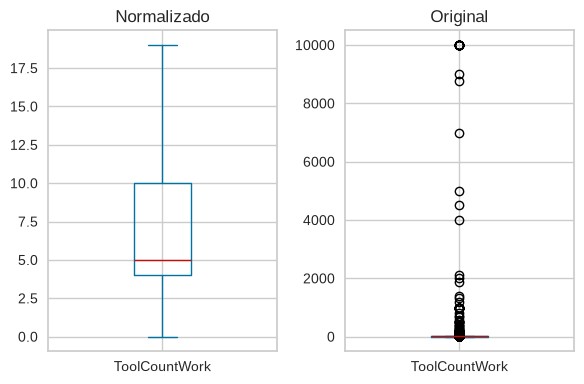

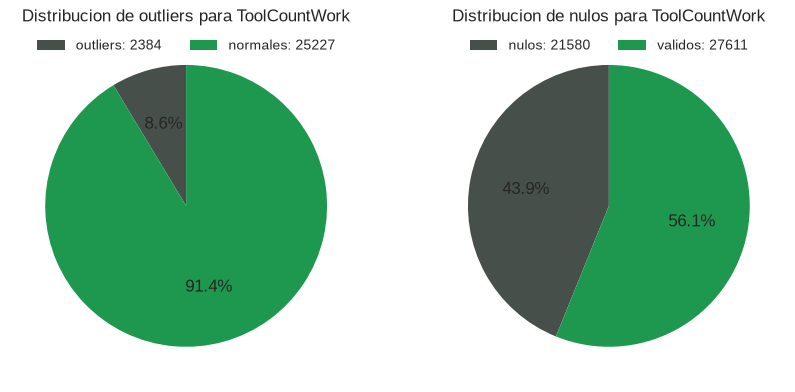

-------------------------------------------------------------------------------------------


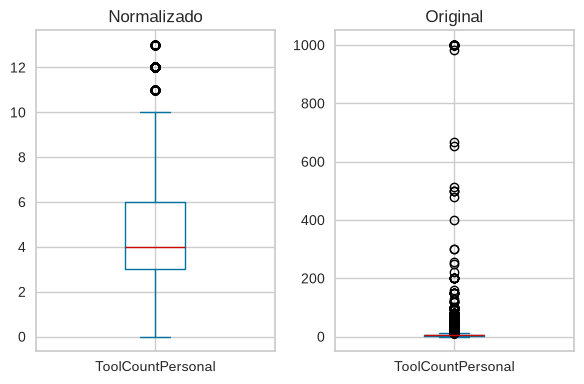

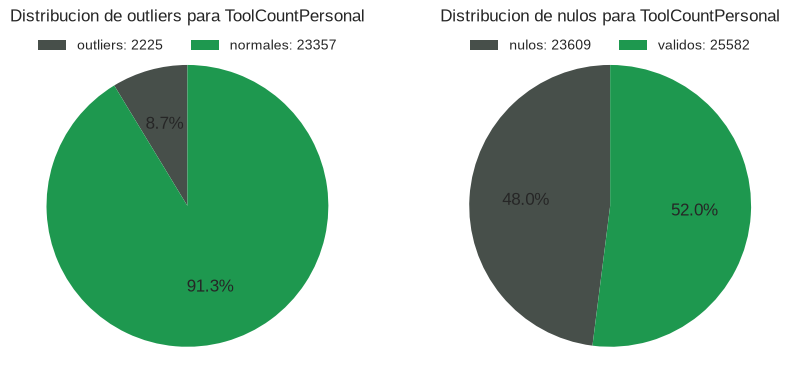

-------------------------------------------------------------------------------------------


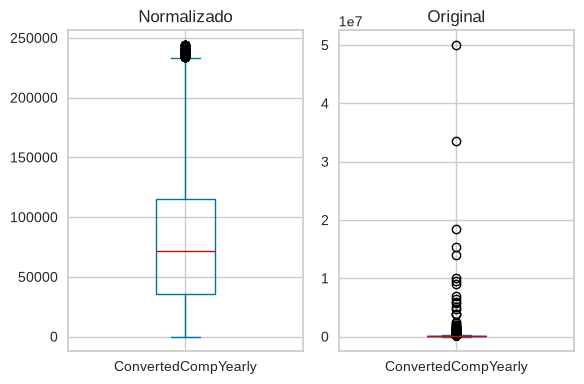

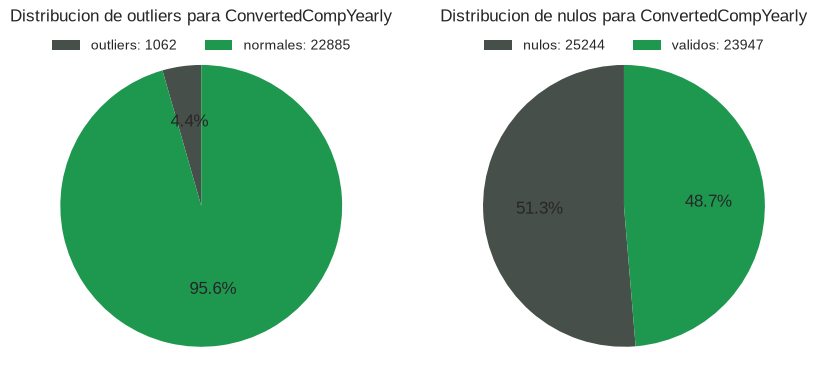

-------------------------------------------------------------------------------------------


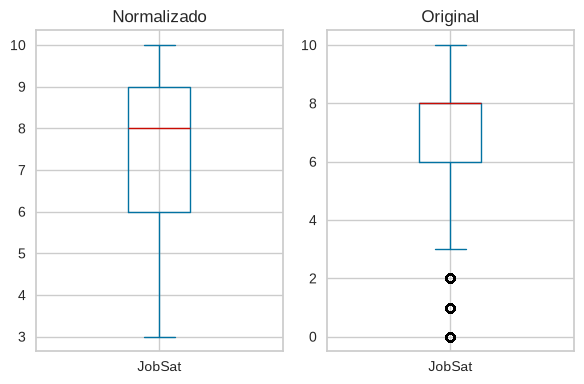

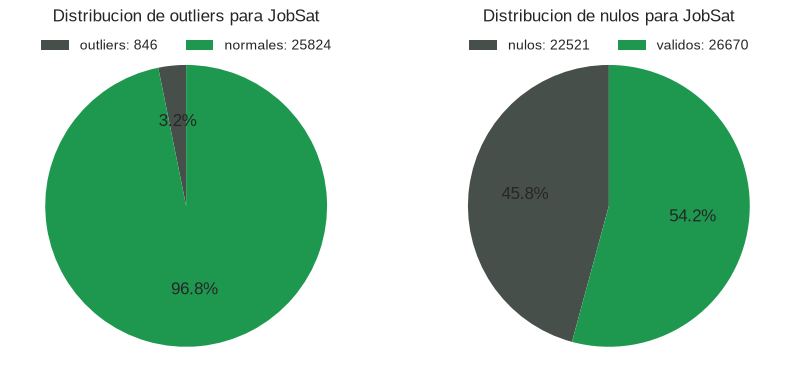

-------------------------------------------------------------------------------------------


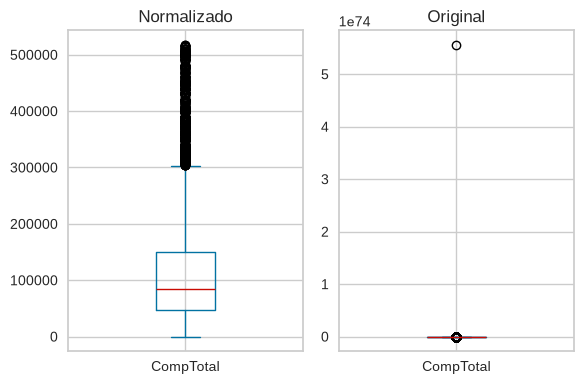

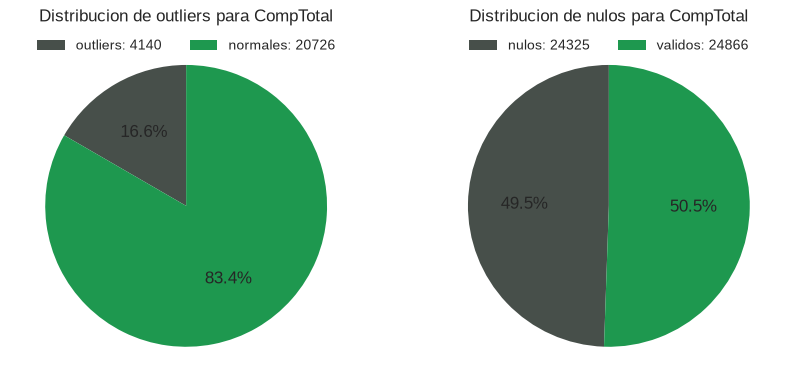

-------------------------------------------------------------------------------------------


In [465]:
data = df.copy()
cols = [
    'ToolCountWork',
    'ToolCountPersonal',
    'ConvertedCompYearly',
    'JobSat',
    'CompTotal'
]
for i in cols:
    utils.box_plot_comparative(data, i)
    utils.graph_nulls_outliers(data, i)
    out, _ = utils.get_ranges(data, i)
    print('-------------------------------------------------------------------------------------------')

<h4><u>Experencia y aprendizaje

In [466]:
dash2 = ds.Dashboard(columns=4, figsize=(20, 4))

In [467]:
columnas2 = [
    'WorkExp',
    'YearsCode',
    'LearnCodeChoose',
    'LearnCode',
    'LearnCodeAI',
    'AILearnHow',
]
dash2.add.multiple_hist(df, columnas2, bins=12)
maping_and_add('LearnCodeChoose', ['yes - master', 'no - master', 'yes = junr'], 0, dash2)
#maping_and_add('LearnCode', [], 0, dash2)
maping_and_add('LearnCodeAI', ['IA_Prof', 'IA_Pers', 'NoIA_Pers', 'No_learn', 'NoIA_Prof'], 0, dash2)
#maping_and_add('AILearnHow', [], 0, dash2)

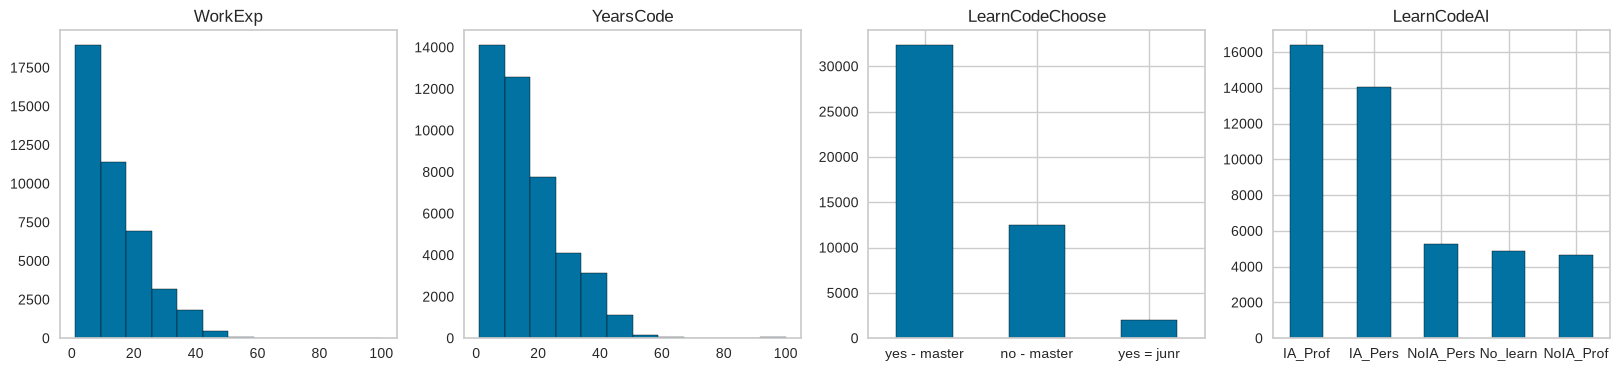

In [468]:
dash2.show()

Analizamos un poco mas a profundidad `WorkExpr` y `YearsCode`.

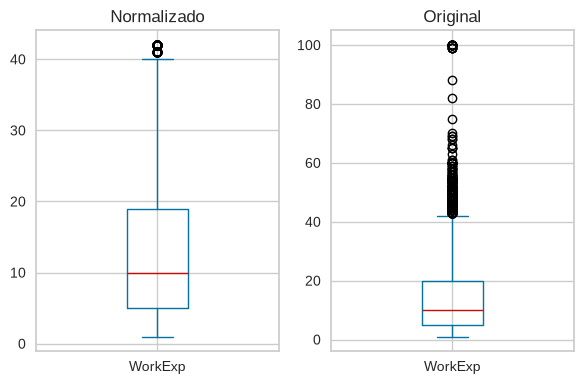

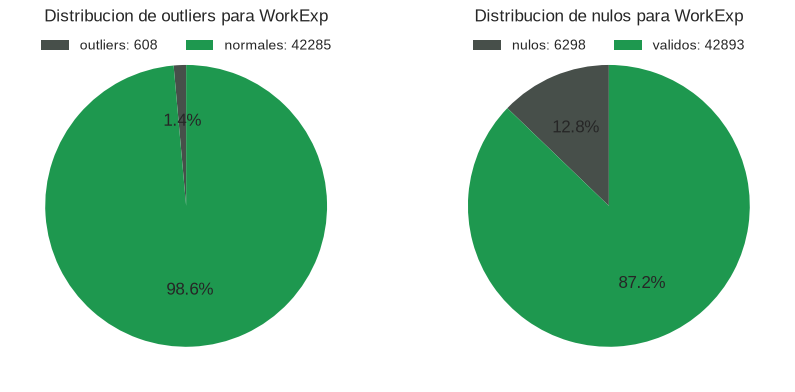

-------------------------------------------------------------------------------------------


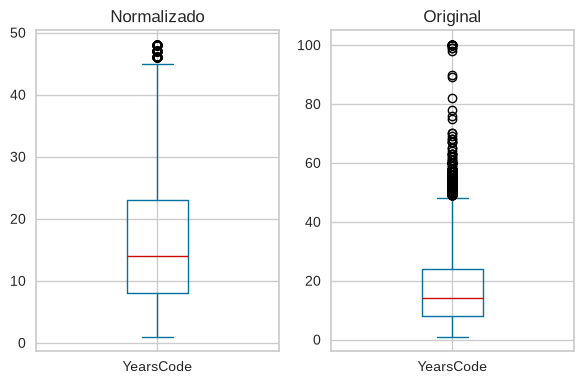

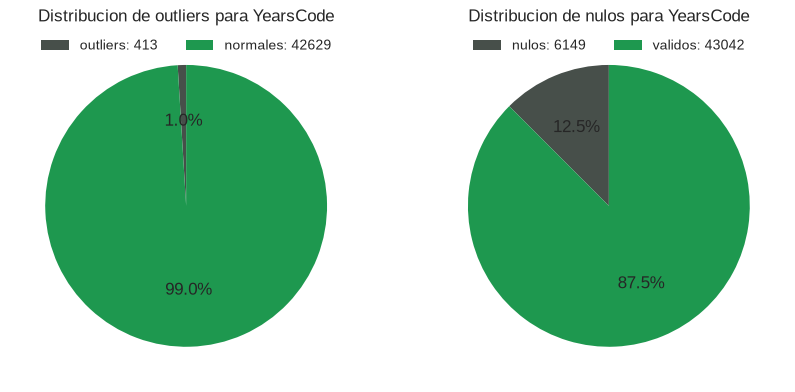

-------------------------------------------------------------------------------------------


In [469]:
data = df.copy()
cols = ['WorkExp', 'YearsCode']
for i in cols:
    utils.box_plot_comparative(data, i)
    utils.graph_nulls_outliers(data, i)
    out, _ = utils.get_ranges(data, i)
    print('-------------------------------------------------------------------------------------------')

Claramente ambas variables tienen una distribucion practicamente similar, esto nos puede llegar a decir algo sobre la existencia de correlacion por lo que vamos a observar un grafico de dispersion

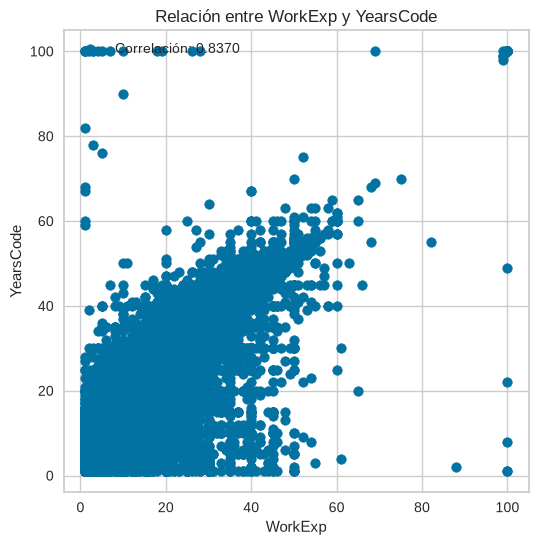

In [470]:
utils.scatter('WorkExp', 'YearsCode', df, alpha=1)

Podemos ver que la relacion es alta, por lo que los anios de escritura de codigo nos puede llegar a servir como un indicar de los anios de experencia trabajados teoricos teniendo sentido porque la gran mayoria de desarrolladores crecen en ambos ejes a lo largo del tiempo.

<h4><u>Stack Tecnológico y Herramientas

In [471]:
dash3 = ds.Dashboard(columns=4, figsize=(20, 4))

In [472]:
def all_columns(df, start, values_change=[], min=0, ignored=None):
    sub = df.loc[:, df.columns.str.startswith(start)]
    for i in sub:
        if i != start + 'Choice' and (not ignored or i != start + ignored):
            maping_and_add(i, values_change, min, dash3, multiple=True)

In [473]:
# TODO: Sacar antes de entrega
columnas3 = [
    'LanguageChoice',
    'LanguageHaveWorkedWith',
    'LanguageWantToWorkWith',
    'LanguageAdmired',
    'DatabaseChoice',
    'DatabaseHaveWorkedWith',
    'DatabaseWantToWorkWith',
    'DatabaseAdmired',
    'PlatformChoice',
    'PlatformHaveWorkedWith',
    'PlatformWantToWorkWith',
    'PlatformAdmired',
    'WebframeChoice',
    'WebframeHaveWorkedWith',
    'WebframeWantToWorkWith',
    'WebframeAdmired',
    'DevEnvsChoice',
    'DevEnvsHaveWorkedWith',
    'DevEnvsWantToWorkWith',
    'DevEnvsAdmired',
    'OpSysPersonal use',
    'OpSysProfessional use',
    'OfficeStackAsyncHaveWorkedWith',
    'OfficeStackAsyncWantToWorkWith',
    'OfficeStackAsyncAdmired',
    'CommPlatformHaveWorkedWith',
    'CommPlatformWantToWorkWith',
    'CommPlatformAdmired',
    'AIModelsChoice',
    'AIModelsHaveWorkedWith',
    'AIModelsWantToWorkWith',
    'AIModelsAdmired',
]

In [474]:
dash3.add.bar(df, 'LanguageChoice', 0)
all_columns(df, 'Language', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 10000, 'Admired')
maping_and_add('LanguageAdmired', ['Js', 'HT/CS', 'SQL', 'Py', 'Sh', 'Ts'], 5000, dash3, multiple=True)

In [475]:
dash3.add.bar(df, 'DatabaseChoice', 0)
maping_and_add('DatabaseHaveWorkedWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 7000, dash3, multiple=True)
maping_and_add('DatabaseWantToWorkWith', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)
maping_and_add('DatabaseAdmired', ['Postgres', 'MySQL', 'SQLite', 'MSSQL', 'Redis'], 3000, dash3, multiple=True)

In [476]:
dash3.add.bar(df, 'PlatformChoice', 0)
maping_and_add('PlatformHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 6900, dash3, multiple=True)
maping_and_add('PlatformWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('PlatformAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)

In [477]:
dash3.add.bar(df, 'WebframeChoice', 0)
maping_and_add('WebframeHaveWorkedWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeWantToWorkWith', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 3000, dash3, multiple=True)
maping_and_add('WebframeAdmired', ['Docker', 'npm', 'AWS', 'Pip', 'K8s'], 1000, dash3, multiple=True)

In [478]:
dash3.add.bar(df, 'DevEnvsChoice', 0)
maping_and_add('DevEnvsHaveWorkedWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsWantToWorkWith', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 3000, dash3, multiple=True)
maping_and_add('DevEnvsAdmired', ['VSC', 'VS', 'Not++', 'IntJ', 'Vim', 'Curs'], 1000, dash3, multiple=True)

In [479]:
maping_and_add('OfficeStackAsyncHaveWorkedWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncWantToWorkWith', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 3000, dash3, multiple=True)
maping_and_add('OfficeStackAsyncAdmired', ['GH', 'Jira', 'GL', 'MD', 'Confl'], 1000, dash3, multiple=True)

In [480]:
maping_and_add('CommPlatformHaveWorkedWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformWantToWorkWith', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 3000, dash3, multiple=True)
maping_and_add('CommPlatformAdmired', ['SO', 'GH', 'YT', 'Redd', 'SE', 'Disc', 'Link'], 1000, dash3, multiple=True)

In [481]:
dash3.add.bar(df, 'AIModelsChoice', 0)
maping_and_add('AIModelsHaveWorkedWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsWantToWorkWith', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 3000, dash3, multiple=True)
maping_and_add('AIModelsAdmired', ['GPT', 'CS', 'GF', 'OAI-R', 'OAI-I', 'GP', 'Deep R'], 1000, dash3, multiple=True)

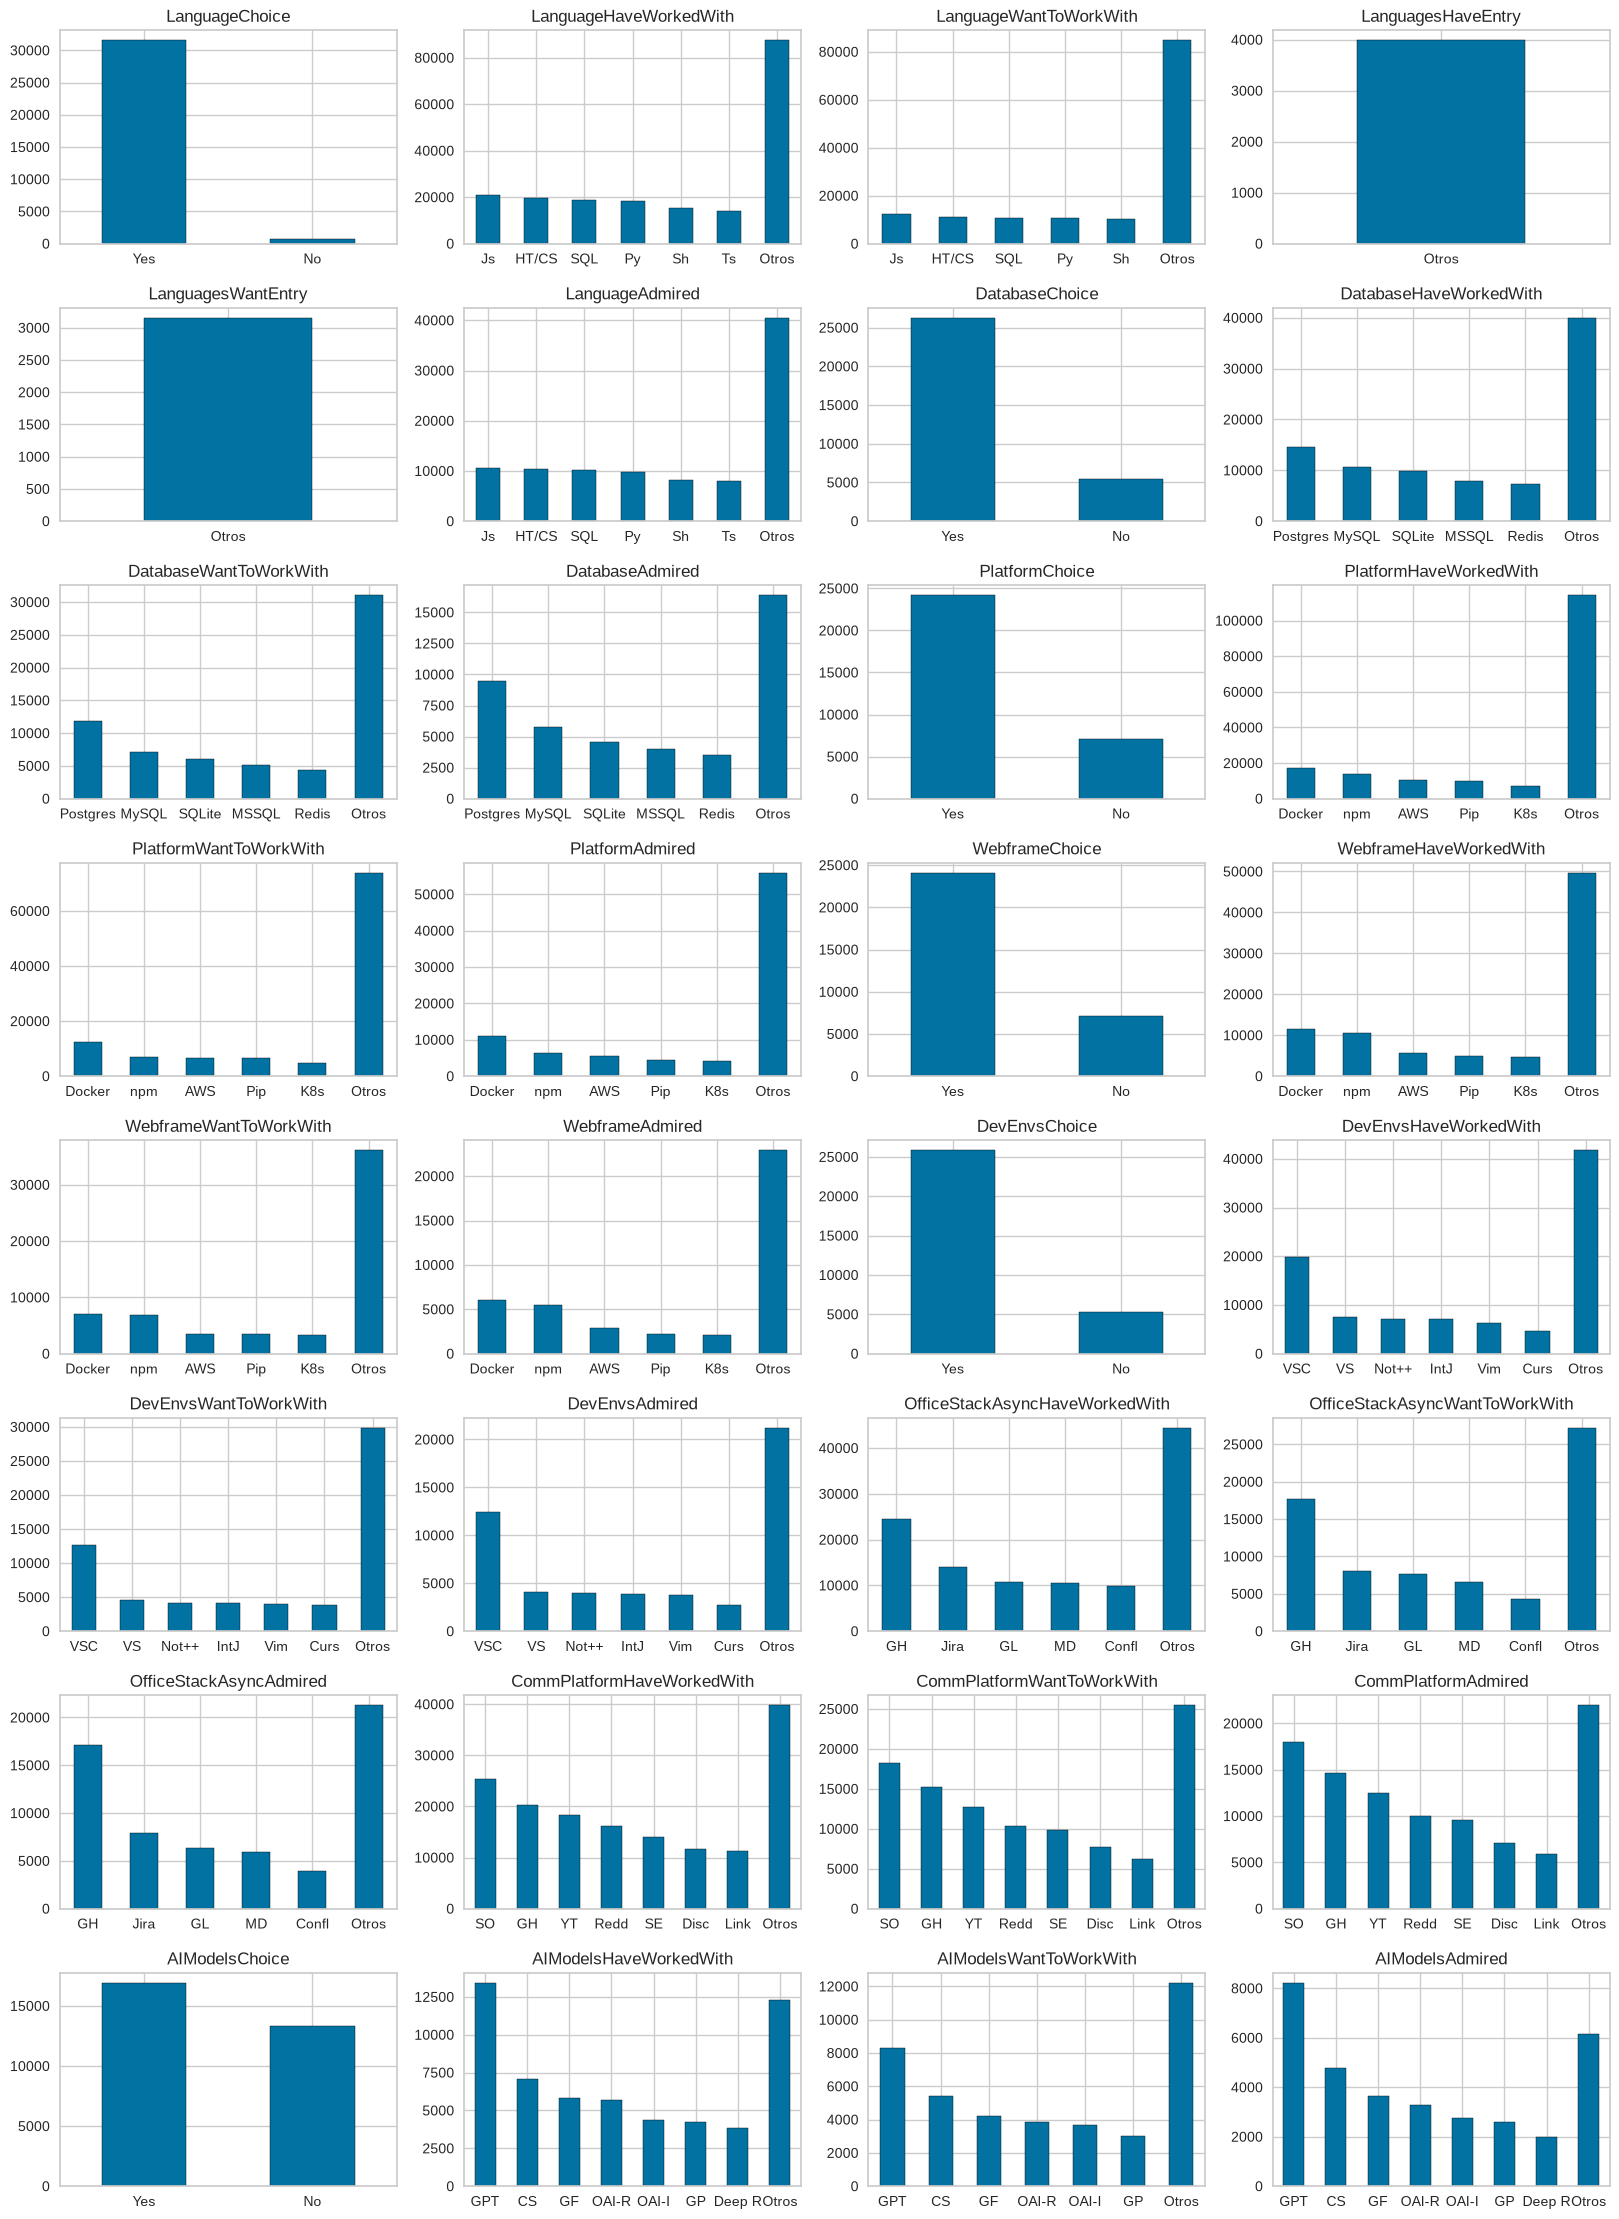

In [482]:
dash3.show()

<h3 style="color: violet;">Correlaciones

En este analisis solo encontramos, para variables cuantitativas, una relacion fuerte explicada anteriormente mediante el par (`WorkExp`, `YearsCode`).

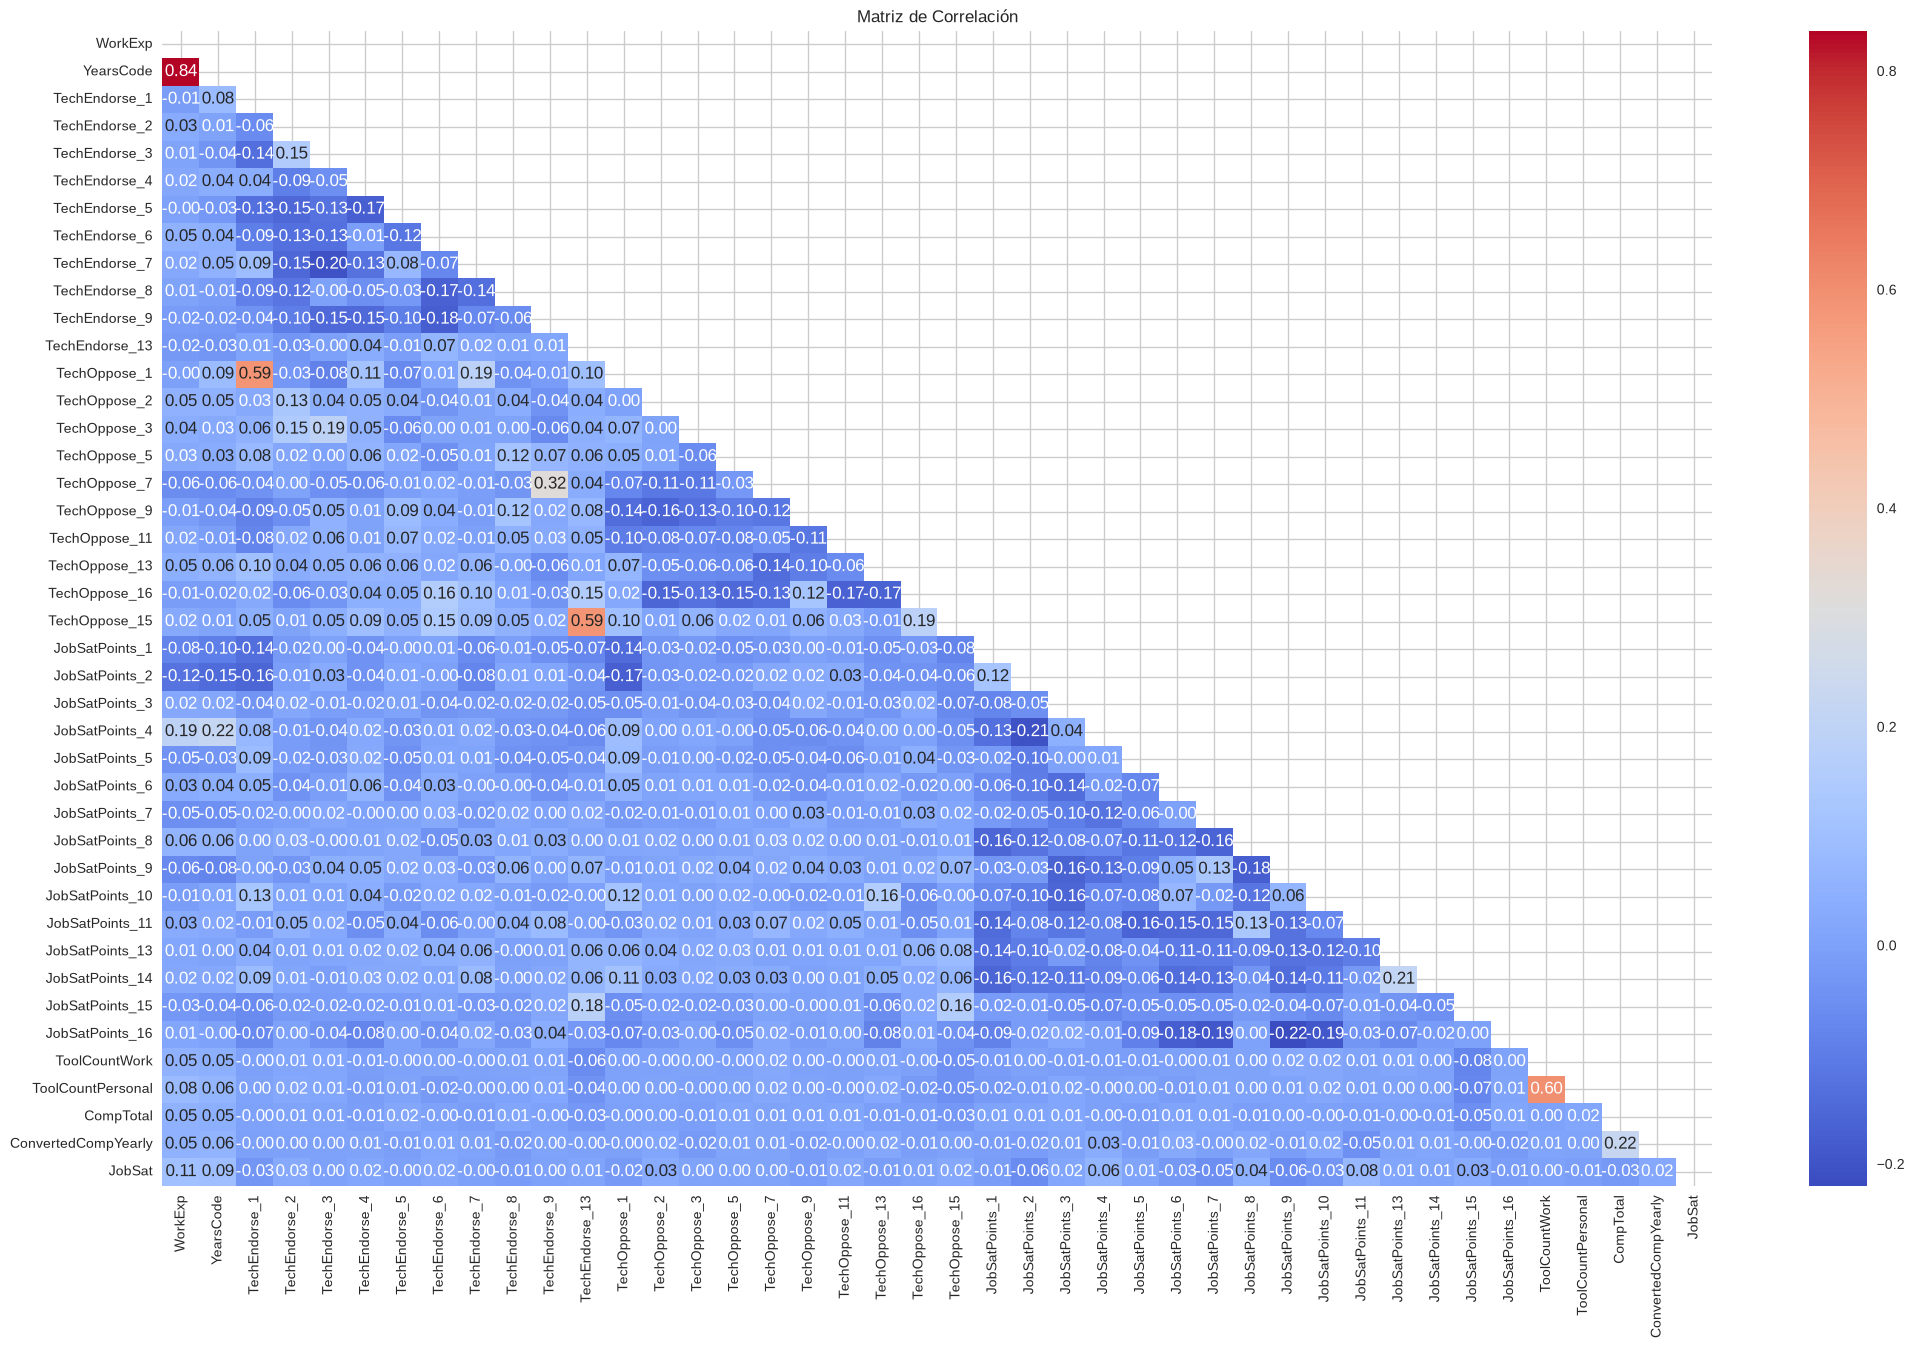

In [483]:
data = df.select_dtypes(include='number')
data = data.loc[:, ~data.columns.str.startswith('SO')]

correlation_matrix = data.drop(columns=['ResponseId']).corr()

mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

plt.figure(figsize=(25, 15))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)
plt.title('Matriz de Correlación')
plt.show()

Claramente podemos ver relaciones como
- `WorkExp` con `YearsCode`.
- `ToolCountWork` con `ToolCountPersonal`.
- `TechOppose_15` con `TechEndorse_13`.
- `TechOppose_1` con `TechEndorse_1`.

Aun asi, estas relaciones no nos aportan mucha informacion ya que explican practicamente lo mismo.

<h1 style="color: orange;">Limpieza de datos

<h3 style="color: violet;">Reduccion de variables a considerar durante el analisis de datos

In [484]:
clean_metadatos = metadatos

<h4><u>Variables de respuesta libre

Analizando el dataset de metadatos, vemos que son aquellas que tienen como tipo de respuesta admitida ('type'):
- TE (Text Entry)
- RO (Ranking Order) con ('sub') = TEXT

In [485]:
columns_save = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'CompTotal'
]
var_free = metadatos[(metadatos['type'] == 'TE') | (metadatos['sub'].str.contains('Text'))]
var_free = var_free[~var_free['qname'].isin(columns_save)] #salvamos aquellas que necesitamos
clean_metadatos.drop(var_free.index)
var_free[['qname', 'question', 'type', 'sub']].head(6)

,qname,question,type,sub
10,TechEndorse_13_TEXT,What attracts you to a technology or causes yo...,RO,Other (please specify): - Text
21,TechOppose_15_TEXT,What would turn you off or cause you to reject...,RO,Other (please specify): - Text
37,JobSatPoints_15_TEXT,Rank the following attributes of your current ...,RO,Other (please specify): - Text
48,SO_Actions_15_TEXT,"When visiting Stack Overflow, which following ...",RO,Other (write in): - Text
77,LanguagesHaveEntry,Was the programming language you use not liste...,TE,NaN
78,LanguagesWantEntry,Was the programming language you want to use n...,TE,NaN


Ademas, realizamos un promedio de porcentajes de valores nulos entre todas las columnas que descartamos y observamos que, en  promedio, el 84% de los valores de estas eran nulos. Observado tambien en el grafico de torta

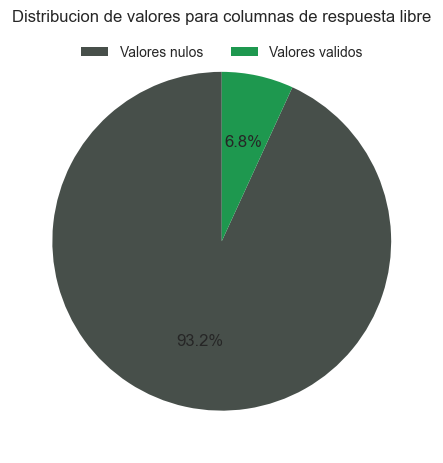

In [486]:
j = percentage_null = 0
cant_null = cant_not_null = 0
for i in var_free['qname']:
    cant_null += df[i].isna().sum()
    cant_not_null += df[i].notna().sum()
    percentage_null += df[i].isna().mean()
    j += 1

percentage_null /= j
print(f"Promedio: {percentage_null} - Cantidad nulos: {cant_null} - Cantidad no nulos: {cant_not_null} - Total: {cant_null + cant_not_null}")

Promedio: 0.93152710861743 - Cantidad nulos: 1283037 - Cantidad no nulos: 94311 - Total: 1377348


In [487]:
df = df.drop(columns=var_free['qname'].to_list(), errors="ignore")

<h4><u>Variables asociadas al uso de StackOverflow

Analizando el dataset de metadatos, vemos que son aquellas que comienzan con 'SO' en el nombre de variable

In [488]:
var_SO = metadatos[metadatos['qname'].str.startswith('SO')]
clean_metadatos.drop(var_SO.index)
var_SO[['qname', 'question']].head(3)

,qname,question
38,SO_Actions_1,"When visiting Stack Overflow, which following ..."
39,SO_Actions_16,"When visiting Stack Overflow, which following ..."
40,SO_Actions_3,"When visiting Stack Overflow, which following ..."


In [489]:
df = df.drop(columns=var_SO['qname'].to_list(), errors="ignore")

<h3 style="color: violet;">Reduccion por redundancia o por alto porcentaje de valores nulos

<h4><u>Variables asociadas a la influencia de compra tecnologica

In [490]:
df = df.drop(columns=['PurchaseInfluence', 'TechEndorseIntro'])

<h4><u>Variables redundantes de moneda y remuneracion local

El Dataset nos aporta la moneda local y su remuneracion en ella para el encuestado en si, pero tambien nos ofrece la conversion a dolares. Por lo que, para trabajar con la misma unidad, nos quedamos con `ConvertedCompYearly`.

In [491]:
df = df.drop(columns=['Currency'])

<h4><u>Registros duplicados

In [492]:
df = df.drop_duplicates()

<h4><u>ID de registros

In [493]:
df = df.drop(columns='ResponseId')

<h4><u>Variables no numericas con un porcentaje de valores nulos altos

Realizamos un analisis para identificar la distribucion de valores nulos en estas variables. Por estandar aplicado por nuestra decision, decidimos eliminar todas aquellas que tienen mas de un 80% de valores nulos en su conjunto.

In [494]:
df.select_dtypes(exclude=['number']).isna().mean().mean()

np.float64(0.4975734545439031)

In [495]:
percentages = df.select_dtypes(exclude=['number']).isna().mean().sort_values(ascending=False)
drop_columns = percentages[percentages > 0.8].index.to_list()
df_80_nulls = pd.DataFrame({
    'Col': drop_columns
})
df_80_nulls

,Col
0,AIAgentObserveSecure
1,AIAgentKnowledge
2,AIAgentOrchestration
3,AIAgentImpactStrongly disagree
4,AIAgentImpactSomewhat disagree
5,AgentUsesGeneral
6,AIAgentImpactStrongly agree
7,AIAgentExternal
8,AIAgentChallengesStrongly disagree
9,AIAgentImpactNeutral


Podemos ver que se tratan de todas variables relacionadas al uso de Inteligencia artificial, por lo que primeramente comprobamos que dichos valores nulos no se correspondan por un valor especifico de la variable `AISelect` que justamente preguntaba el uso o no de dicha herramienta.

In [496]:
df.groupby('AISelect')[df.columns[df.columns.str.startswith('AI')]].apply(
    lambda x: x.isna().mean().mean() * 100
)

AISelect
No, and I don't plan to                        58.619146
No, but I plan to soon                         55.466627
Yes, I use AI tools daily                      39.209699
Yes, I use AI tools monthly or infrequently    48.381336
Yes, I use AI tools weekly                     42.988666
dtype: float64

En definitiva, podemos ver que usen o no el porcentaje de nulos se reparte en iguales. Por lo que decidimos definitivamente eliminar dichas columnmas con altos porcentajes de nulos

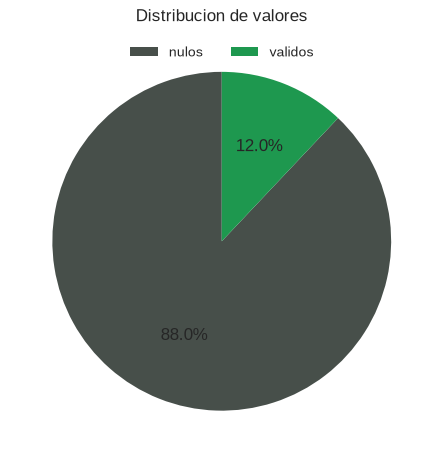

In [497]:
frecuencias = [df[drop_columns].isna().mean().mean(), df[drop_columns].notna().mean().mean()]
labels = ['nulos', 'validos']
utils.pie_chart(df, frecuencias, labels, colors=["#474f4a", '#1e984f'], title='Distribucion de valores')

In [498]:
df = df.drop(columns=drop_columns)

<h3 style="color: violet;">Normalizado de distribuciones de variables numericas

Mediante el analisis inicial, donde observamos un poco mas de cerca variables tales como `WorkExpr`, `YearsCode`, `JobSat`, `ToolCountWork`, `ToolCountPersonal` y `ConvertedCompYearly` que representaban distribuciones un poco extranas, decidimos actuar sobre ellas para eliminar sus valores outliers y obtener como se vio en la comparativa su distribucion "normalizada".

Recordamos que un valor outlier es aquel que se encuentra por debajo de Q1 - 1.5 x IQR o por encima de Q3 + 1.5 x IQR

In [499]:
cols = [
    'WorkExp',
    'YearsCode',
    'ToolCountWork',
    'ToolCountPersonal',
    'ConvertedCompYearly',
    'JobSat'
]
for i in cols:
    out, _ = utils.get_ranges(df, i)
    df = df.drop(out.index)

El objetivo de esta limpieza fue la recuperacion de la distribucion mayoritaria de las variables, donde claramente en `WorkExpr`, `YearsCode`, `ToolCountWork`, `ToolCountPersonal` y `ConvertedCompYearly` pudimos realizar dicha accion de forma muy efectiva.

<h3 style="color: violet;">Reduccion de dimensionalidad

A continuacion vamos a realizar una reduccion de variables capturando solo aquellas cuantitativas junto a variables de nuestro interes como la confianza en la IA, la edad, el tamano de la organizacion y su nivel academico con el objetivo de conocer un poco las relaciones entre ellas.

In [500]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from umap import UMAP

In [501]:
pca = PCA(n_components=2, whiten=False, random_state=10)
tsne = TSNE(n_components=2, random_state=10)
umap = UMAP(n_components=2, random_state=10)

In [502]:
data = df.copy()

Mapeamos las variables cualitativas ordinales

In [503]:
mapa_confianza = {
    'Highly distrust': 0,
    'Somewhat distrust': 1,
    'Neither trust nor distrust': 3,
    'Somewhat trust': 4,
    'Highly trust': 5,
}

data['AIAcc'] = data['AIAcc'].map(mapa_confianza)

In [504]:
mapped = {
    '18-24 years old': 0,
    '25-34 years old': 1,
    '35-44 years old': 2,
    '45-54 years old': 3,
    '55-64 years old': 4,
    '65 years or older': 5,
    'Prefer not to say': np.nan
}

data['Age'] = data['Age'].map(mapped)

In [505]:
edlevel_map = {
    'Primary/elementary school': 0,
    'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)': 1,
    'Some college/university study without earning a degree': 2,
    'Associate degree (A.A., A.S., etc.)': 3,
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": 4,
    "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)": 5,
    'Professional degree (JD, MD, Ph.D, Ed.D, etc.)': 6,
    'Other (please specify):': np.nan
}

data['EdLevel'] = data['EdLevel'].map(edlevel_map)

In [506]:
orgsize_map = {
    'Just me - I am a freelancer, sole proprietor, etc.': 0,
    'Less than 20 employees': 1,
    '20 to 99 employees': 2,
    '100 to 499 employees': 3,
    '500 to 999 employees': 4,
    '1,000 to 4,999 employees': 5,
    '5,000 to 9,999 employees': 6,
    '10,000 or more employees': 7,
    "I don’t know": np.nan
}
data['OrgSize'] = data['OrgSize'].map(orgsize_map)

In [507]:
mapped = {
    'Yes': 1,
    'No': 0
}
data['DatabaseChoice'] = data['DatabaseChoice'].map(mapped)
data['LanguageChoice'] = data['LanguageChoice'].map(mapped)
data['PlatformChoice'] = data['PlatformChoice'].map(mapped)
data['WebframeChoice'] = data['WebframeChoice'].map(mapped)
data['DevEnvsChoice'] = data['DevEnvsChoice'].map(mapped)
data['AIModelsChoice'] = data['AIModelsChoice'].map(mapped)

In [508]:
var_objetivo = 'WorkExp'

In [509]:
cols = ['YearsCode', 'WorkExp', 'ConvertedCompYearly', 'JobSat','Age', 'EdLevel', 'OrgSize', 'ToolCountWork', 'AIAcc']
data1 = data[cols].dropna()

In [510]:
def scale(data, var_objetivo):
    scaler = StandardScaler()
    X_to_scale = data.drop(columns=[f'{var_objetivo}'])

    df_scaled = pd.DataFrame(
        scaler.fit_transform(X_to_scale),
        columns=X_to_scale.columns,
        index=X_to_scale.index
    )
    return df_scaled, X_to_scale

In [511]:
df_scaled, X_to_scale = scale(data1, var_objetivo)

In [512]:
principalComponents_pca = pca.fit_transform(df_scaled)
principalComponents_tsne = tsne.fit_transform(df_scaled)
principalComponents_umap = umap.fit_transform(df_scaled)

/media/discoD/Facultad-IS/4to año/Fundamentos de la Ciencia de Datos (copia)/TPE/ciencia-datos-tpe/venv_tpe/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/media/discoD/Facultad-IS/4to año/Fundamentos de la Ciencia de Datos (copia)/TPE/ciencia-datos-tpe/venv_tpe/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [513]:
def graficar_comparativa(data):
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))

    ax[0].scatter(principalComponents_pca[:, 0], principalComponents_pca[:, 1], c=data[f'{var_objetivo}'], cmap='viridis', alpha=1)
    ax[0].grid(True)
    ax[0].set_xlabel('Proyección PCA 1')
    ax[0].set_ylabel('Proyección PCA 2')
    ax[0].set_title('Proyección PCA')

    ax[1].scatter(principalComponents_tsne[:, 0], principalComponents_tsne[:, 1], c=data[f'{var_objetivo}'], cmap='viridis', alpha=1)
    ax[1].grid(True)
    ax[1].set_xlabel('Proyección t-SNE 1')
    ax[1].set_ylabel('Proyección t-SNE 2')
    ax[1].set_title('Proyección t-SNE')

    ax[2].scatter(principalComponents_umap[:, 0], principalComponents_umap[:, 1], c=data[f'{var_objetivo}'], cmap='viridis', alpha=1)
    ax[2].grid(True)
    ax[2].set_xlabel('Proyección UMAP 1')
    ax[2].set_ylabel('Proyección UMAP 2')
    ax[2].set_title('Proyección UMAP')

    plt.colorbar(ax[0].collections[0])
    plt.colorbar(ax[1].collections[0])
    plt.colorbar(ax[2].collections[0])
    plt.tight_layout()
    plt.show()

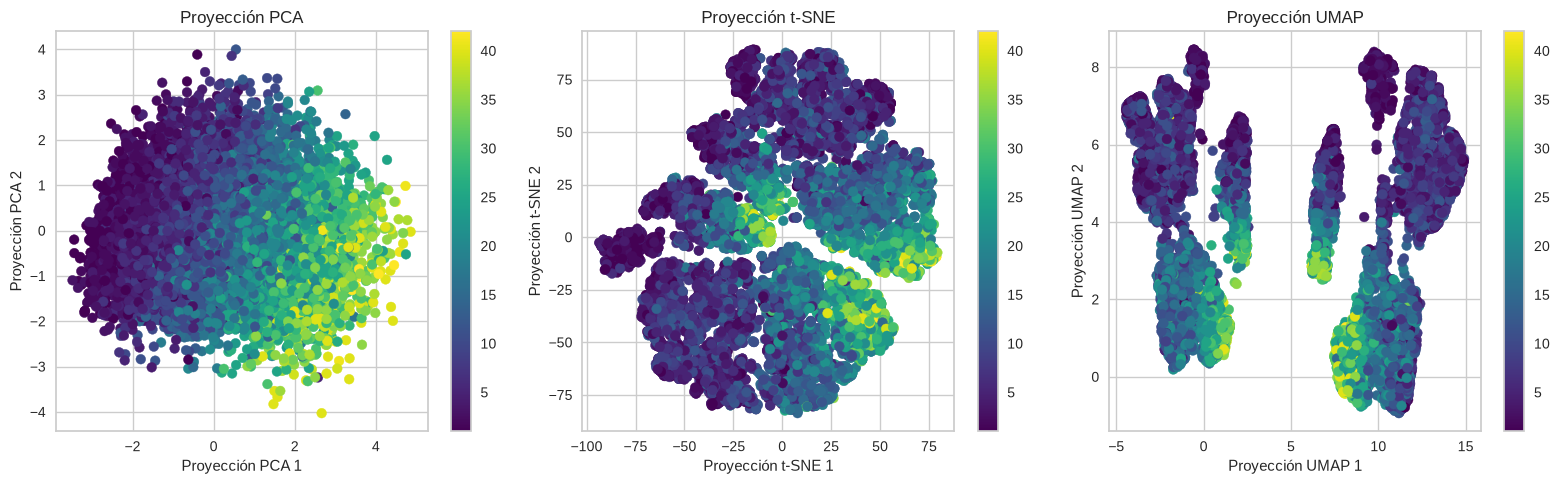

In [514]:
graficar_comparativa(data1)

In [515]:
pca.explained_variance_ratio_[:2]

array([0.26948723, 0.14186774])

Aunque no tengamos una alta varianza explicada por parte de 2 componentes de PCA, vemos que la primera componente del PCA puede llegar a explicar un patron del salario anual, es decir, a mayor valor en PCA1 mayor salario anual.

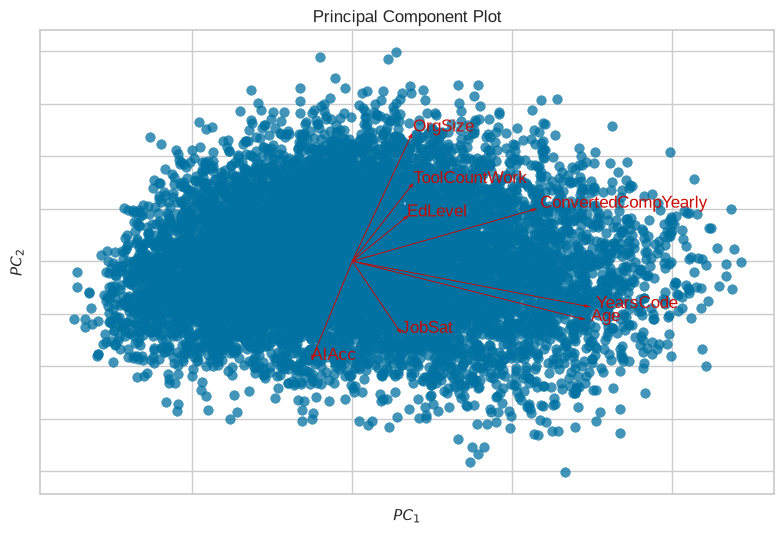

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [516]:
from yellowbrick.features import PCA as PcaViz

viz = PcaViz(
    scale=False,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
    features=X_to_scale.columns.to_list()
)
viz.fit_transform(df_scaled)
viz.show()

In [517]:
loadings = pd.DataFrame(
    viz.pca_components_.T,
    index=X_to_scale.columns.to_list(),
    columns=["PC1", "PC2"]
)
loadings.sort_values("PC1", ascending=False)

,PC1,PC2
YearsCode,0.598202,-0.212684
Age,0.585405,-0.271863
ConvertedCompYearly,0.460978,0.242722
ToolCountWork,0.149775,0.354828
OrgSize,0.148965,0.589584
EdLevel,0.134359,0.203304
JobSat,0.119190,-0.325594
AIAcc,-0.100370,-0.448426


Tenemos que los anios de codeo, edad misma y el salario anual son los que mas aportan al crecimiento de los anios de experencia.

Mediante este Biplot podemos ver que nos sirve los angulos existentes entre los vectores ya que estos indican que tan correlacionados estan entre si las variables. Asi, este analisis de reduccion de dimensionalidad nos sirvio para identificar una posible relacion lineal de los anios de experencia laboral con el conjunto de variables anteriormente usadas que vamos a estar probando mas adelante en la hipotesis multivariada. Ademas, de este mismo analisis nos surgio la duda de si dependiendo la confianza en la IA puede llegar a haber diferencias significativas en el salario anual (lo vemos en la hipotesis bivariada).

Igualmente, vamos a ver cuantas componentes necesitariamos para representar una varianza considerable de los datos.

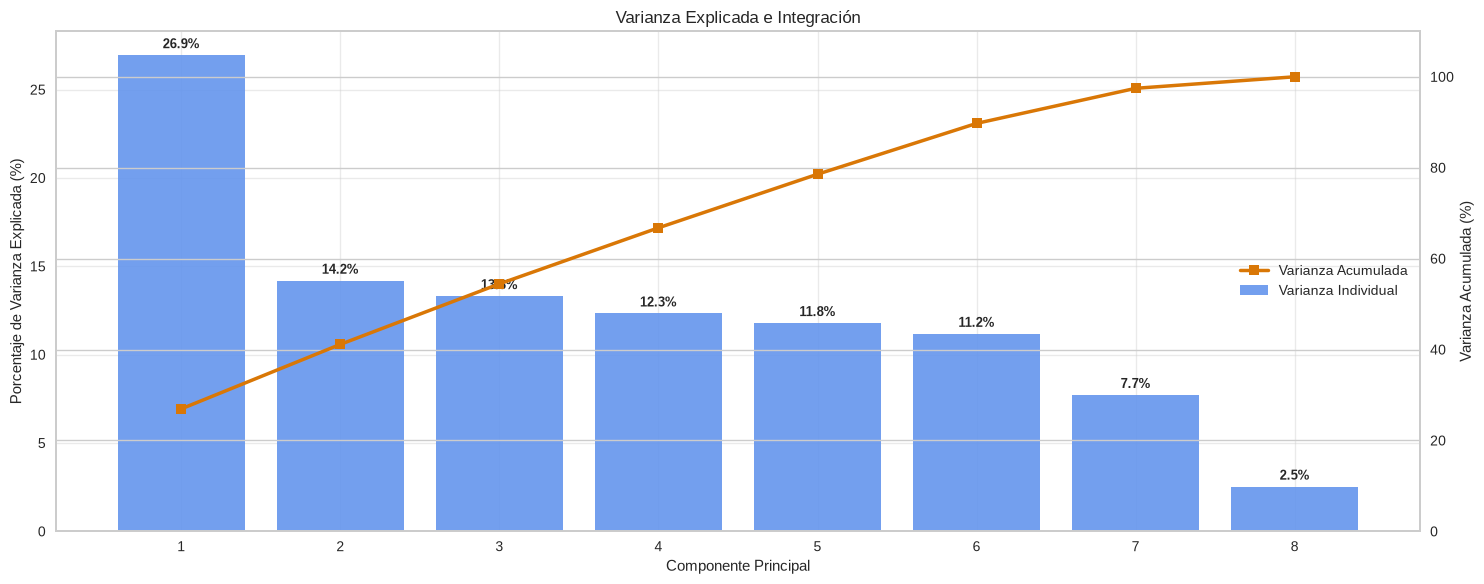

In [518]:
# Componentes necesarias para porcentajes de varianza explicada
pca = PCA()
pca.fit_transform(df_scaled)
# Calcular porcentajes
varianza_individual = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza_individual)

componentes = np.arange(1, len(varianza_individual) + 1)

# Crear gráfico
fig, ax1 = plt.subplots(figsize=(15, 6))

# Barras: varianza individual
ax1.bar(
    componentes,
    varianza_individual,
    color="cornflowerblue",
    alpha=0.9,
    label="Varianza Individual"
)

ax1.set_xlabel("Componente Principal")
ax1.set_ylabel("Porcentaje de Varianza Explicada (%)")
ax1.set_xticks(componentes)
ax1.set_title("Varianza Explicada e Integración")
ax1.grid(axis="both", alpha=0.4)
ax1.set_axisbelow(True)

# Etiquetas sobre las barras
for x, y in zip(componentes, varianza_individual):
    ax1.annotate(
        f"{y:.1f}%",
        (x, y),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

# Línea: varianza acumulada
ax2 = ax1.twinx()
ax2.plot(
    componentes,
    varianza_acumulada,
    color="#d97706",
    marker="s",
    linewidth=2.5,
    label="Varianza Acumulada"
)

ax2.set_ylabel("Varianza Acumulada (%)")
ax2.set_ylim(0, 110)

# Leyenda combinada
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    handles2 + handles1,
    labels2 + labels1,
    loc="center right"
)

plt.tight_layout()
plt.show()

Mediante este grafico demostramos que deberiamos recaudar muchas mas componentes para explicar una variabilidad total de los datos mayor.

In [519]:
var_objetivo = 'ConvertedCompYearly'

In [520]:
cols = ['YearsCode', 'WorkExp', 'ConvertedCompYearly', 'JobSat','Age', 'EdLevel', 'OrgSize', 'ToolCountWork', 'DatabaseChoice', 'LanguageChoice', 'PlatformChoice', 'WebframeChoice', 'DevEnvsChoice', 'AIModelsChoice']
data2= data[cols].dropna()

In [521]:
df_scaled, X_to_scale = scale(data2, var_objetivo)

In [522]:
principalComponents_pca = pca.fit_transform(df_scaled)
principalComponents_tsne = tsne.fit_transform(df_scaled)
principalComponents_umap = umap.fit_transform(df_scaled)

/media/discoD/Facultad-IS/4to año/Fundamentos de la Ciencia de Datos (copia)/TPE/ciencia-datos-tpe/venv_tpe/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


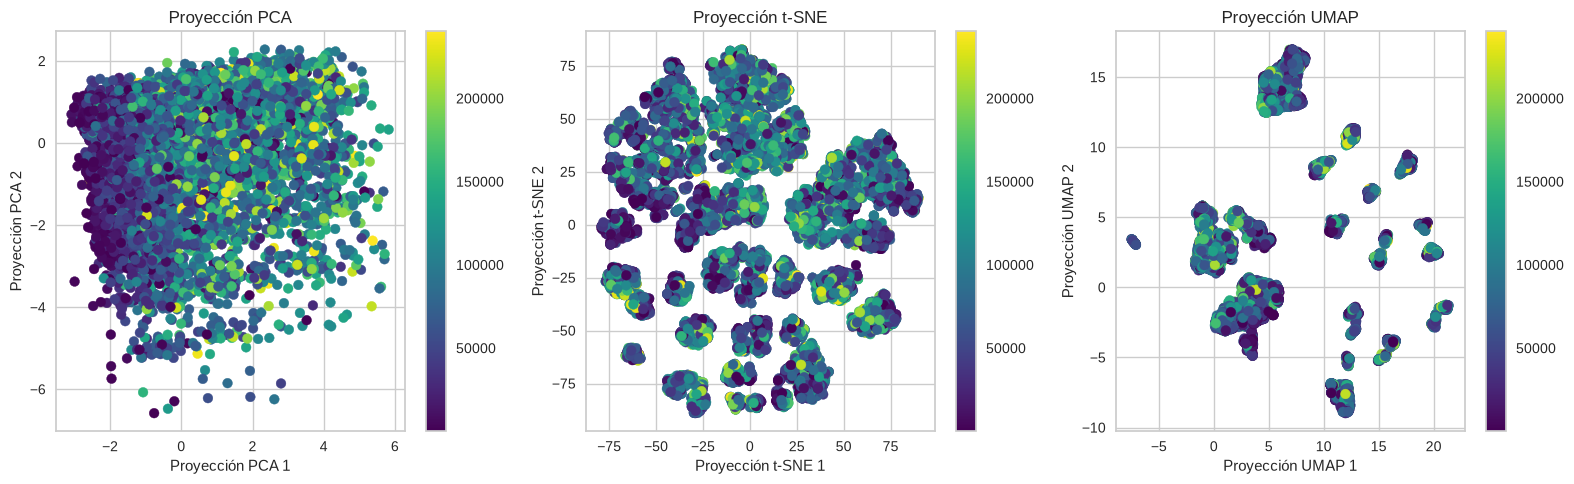

In [523]:
graficar_comparativa(data2)

In [524]:
pca.explained_variance_ratio_[:2]

array([0.21297284, 0.1417861 ])

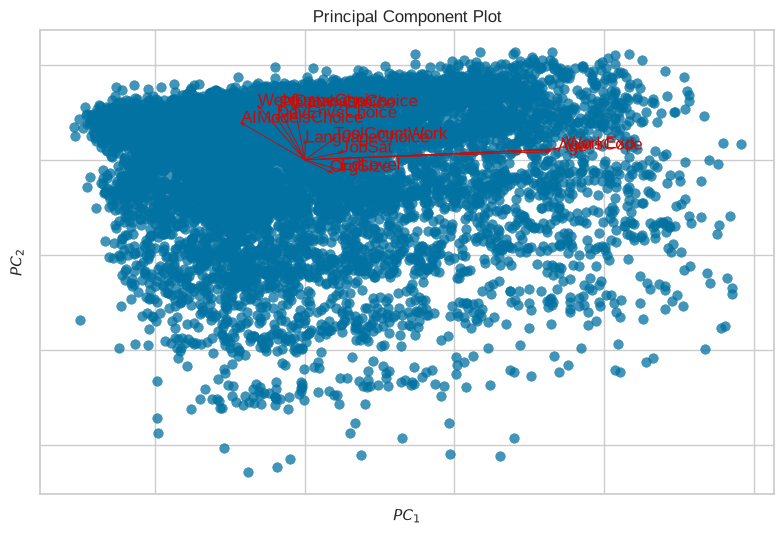

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [525]:
viz = PcaViz(
    scale=False,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
    features=X_to_scale.columns.to_list()
)
viz.fit_transform(df_scaled)
viz.show()

In [526]:
loadings = pd.DataFrame(
    viz.pca_components_.T,
    index=X_to_scale.columns.to_list(),
    columns=["PC1", "PC2"]
)
loadings.sort_values("PC1", ascending=False)

,PC1,PC2
WorkExp,0.570474,0.100683
YearsCode,0.559369,0.089510
Age,0.552570,0.073116
EdLevel,0.078174,-0.089565
JobSat,0.077935,0.063748
ToolCountWork,0.063760,0.183848
OrgSize,0.054635,-0.105076
LanguageChoice,0.001113,0.152226
DatabaseChoice,-0.021947,0.469577
PlatformChoice,-0.055599,0.454865


A simple vista se puede llegar a ver una relacion donde la componente 1 explica, a traves de `YearsCode`, `WorkExp` y `Age`, el crecimiento del sueldo pero tenemos que comprobarlo mediante una regresion lineal que abordaremos en la hipotesis multivariada.

<h1 style="color: orange;">Validacion de hipotesis

<h3 style="color: violet;">Univariada

<h4><u>De aquellos desarrolladores que no tienen miedo a que la Inteligencia Artificial reemplace su trabajo, su experiencia laboral es superior a 5 años (se consideran seniors).

Mediante el Biplot observado en el analisis de reduccion de dimensionalidad pudimos observar como la confianza en la IA tenia una correlacion negativa con la componente principal 1 que explicaba en si el crecimiento de los anios de experiencia, por lo que queremos verificar que de aquellos que no confian de la IA su experiencia laboral sea superior a 5 anios.

In [527]:
devs = df[df['AIThreat'] == 'No']

Vamos a usar un test de Student para una muestra planteando hipotesis a una cola. Es decir, planteamos que la hipotesis nula suponga que la media de anios de experencia laboral se encuentra por igual o debajo de 5 anios y que la hipotesis alternativa suponga lo contrario.

Por el teorma del limite central, podemos no comprobar la normalidad de la muestra gracias a que la media de la misma muestra tiende a una distribucion normal con un n > 30.

Planteamos
- H0: u <= 5
- H1: u > 5

In [528]:
valor_referencia = 5

t_statistic, p_value = stats.ttest_1samp(
    devs['WorkExp'].dropna(),
    popmean=valor_referencia,
    alternative='greater'
)

print(f"Estadístico t: {t_statistic:.3f}")
print(f"p-valor: {p_value:.3f}")

Estadístico t: 106.194
p-valor: 0.000


Asi, dado p-valor < 0.05, rechazamos la hipotesis nula y aceptamos que la media de los anios de experencia es significativamente superior a 5 anios.

<h4><u>De los desarrolladores que no tienen miedo a que la Inteligencia Artificial reemplace su trabajo, la proporcion de aquellos que poseen al menos una carrera de grado es superior de los que no tienen.

Mediante el Biplot observado en el analisis de reduccion de dimensionalidad pudimos observar como la confianza en la IA tenia una correlacion negativa con el nivel educativo, por lo que decidimos ampliar el analisis y experimentar con aquellos que no tienen miedo a que la IA reemplace su trabajo para verificar si es que la proporcion dicha del grupo se encuentra explicada mayormente por que tienen una carrera de grado o superior.

In [529]:
df['EdLevel'].value_counts()

EdLevel
Bachelor’s degree (B.A., B.S., B.Eng., etc.)                                          17718
Master’s degree (M.A., M.S., M.Eng., MBA, etc.)                                       10898
Some college/university study without earning a degree                                 5326
Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)     3262
Professional degree (JD, MD, Ph.D, Ed.D, etc.)                                         2137
Associate degree (A.A., A.S., etc.)                                                    1348
Other (please specify):                                                                 599
Primary/elementary school                                                               528
Name: count, dtype: int64

In [530]:
devs = df[df['AIThreat'] == 'No']

In [531]:
mapped = {
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": 1,
    'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)': 1,
    'Professional degree (JD, MD, Ph.D., Ed.D., etc.)': 1,

    'Some college/university study without earning a degree': 0,
    'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)': 0,
    'Associate degree (A.A., A.S., etc.)': 0,
    'Other (please specify):': 0,
    'Primary/elementary school': 0
}
    
devs['EdLevel'] = devs['EdLevel'].map(mapped)

In [532]:
from statsmodels.stats.proportion import proportions_ztest

# Contamos los casos en los que los desarrolladores no tienen un título universitario
count = devs[devs['EdLevel'] == 1].shape[0]
n = len(devs)

value = 0.67
z_stat, p_value = proportions_ztest(count, n, value, alternative='larger')
print(f"Proporción real: {(count / n):.2%}")
print(f"Estadístico Z: {z_stat:.4f}")
print(f"P-valor: {p_value:.4e}")

Proporción real: 68.24%
Estadístico Z: 3.6891
P-valor: 1.1254e-04


<h4><u>Los desarrolladores que respondieron la encuesta de Argentina tienen un salario 3 veces mayor al Salario Mínimo, Vital y Móvil (SMVM)

In [533]:
cols = [
    'CompTotal', 
    'Country'
]

df_4a = df[df['Country'] == 'Argentina'][cols].copy()

Vamos a usar un test de Student para una muestra planteando hipotesis a una cola. Es decir, planteamos que la hipotesis nula suponga que la media de sueldo anual se encuentra por encima de 3 veces el SMVM y que la hipotesis alternativa suponga lo contrario.

Planteamos
- H0: u >= 5
- H1: u < 5

In [534]:
SMVM = (398.800 * 12) * 3

t_statistic, p_value = stats.ttest_1samp(
    df_4a['CompTotal'].dropna(),
    popmean=SMVM,
    alternative='less'
)

print(f"Estadístico t: {t_statistic:.3f}")
print(f"p-valor: {p_value:.3f}")

Estadístico t: 8.030
p-valor: 1.000


Podemos ver que no rechazamos la H0 y concluimos que los desarrolladores de Argentina tienen un salario significtativamente mayor a 3 veces el SMVM.

<h3 style="color: violet;">Bivariada

<h4><u>De aquellos desarrolladores senior que no confian de la IA, estos tienen mejor remuneracion que aquellos que si confian

Tenemos que nuestra variable que describe dicha confianza en la Inteligencia Artifical presenta valores tales como `Confiar hasta cierto punto`, `Desconfiar hasta cierto punto`, `Ni confiar ni desconfiar`, `Alta desconfianza` y `Alta confianza`. Decidimos, que para tener una relacion binaria de confianza o no confianza, mapear dichos valores a 0 o 1 segun corresponda el siguiente criterio:
- Highly distrust: 0
- Somewhat distrust: 0
- Neither trust nor distrust: np.nan
- Somewhat trust: 1
- Highly trust: 1

Por que mapeamos `ni confiar ni desconfiar a nan`? Porque consideramos que es un punto gris que no nos interesa para este analisis

In [535]:
df['AIAcc'].value_counts()

AIAcc
Somewhat trust                8405
Somewhat distrust             7111
Neither trust nor distrust    6000
Highly distrust               5056
Highly trust                   853
Name: count, dtype: int64

In [536]:
data = df.copy()

In [537]:
data = data.dropna(subset=['ConvertedCompYearly'])

In [538]:
mapped = {
    'Highly distrust ': 0,
    'Somewhat distrust': 0,
    'Neither trust nor distrust': np.nan,
    'Somewhat trust': 1,
    'Highly trust': 1
}

data['AIAcc'] = df['AIAcc'].map(mapped)

Separamos dichos grupos anteriormente explicados

In [539]:
devsSenior = data[data['WorkExp'] >= 10].dropna(subset=['ConvertedCompYearly'])
devsNotrust = devsSenior[devsSenior['AIAcc'] == 0]
devsTrust = devsSenior[devsSenior['AIAcc'] == 1]

In [540]:
import seaborn as sns
import matplotlib.pyplot as plt

Vamos a graficar y comparar las distribuciones en cuanto a la remuneracion total anual en dolares para cada grupo

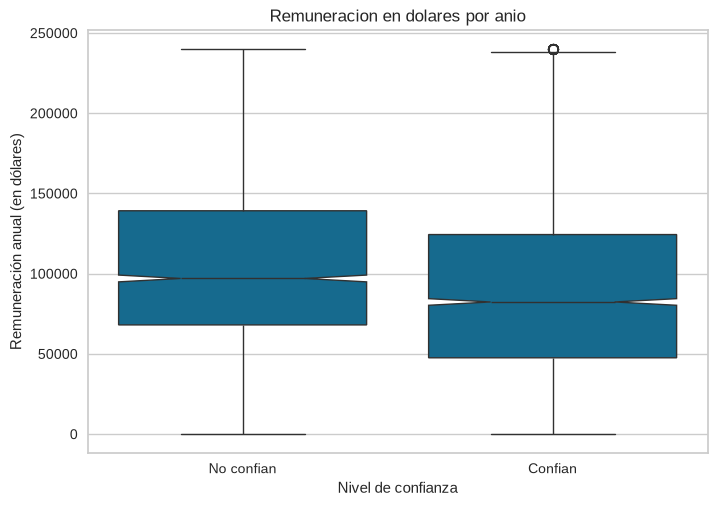

In [541]:
sns.boxplot(x='AIAcc', y='ConvertedCompYearly', data=devsSenior, notch=True)
plt.title("Remuneracion en dolares por anio")
plt.xlabel("Nivel de confianza")
plt.xticks(ticks=[0, 1], labels=["No confian", "Confian"])
plt.ylabel("Remuneración anual (en dólares)")
plt.show()

Pareciera existir diferencias significativas entre ambos grupos pero debemos probarlo estadisticamente. Para ver si podemos usar una prueba t-student para 2 medias verificamos si ambas muestran siguen una distribucion normal y ademas presentan homocedasticidad (igualdad de varianzas).

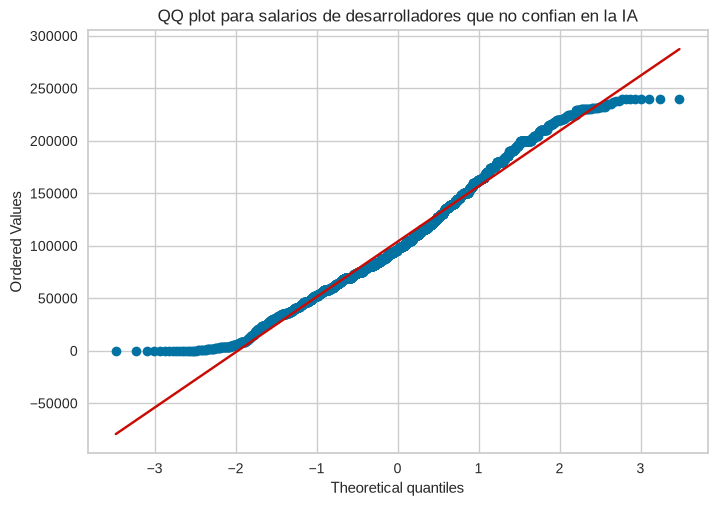

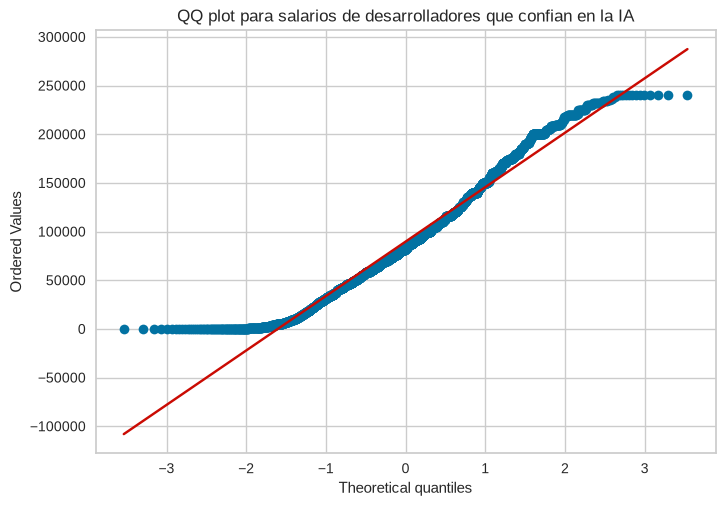

In [542]:
# Salarios de desarrolladores que NO CONFIAN en la IA
stats.probplot(devsNotrust['ConvertedCompYearly'], dist='norm', plot=plt)
plt.title('QQ plot para salarios de desarrolladores que no confian en la IA')
plt.show()

# Salarios de desarrolladores que CONFIAN en la IA
stats.probplot(devsTrust['ConvertedCompYearly'], dist='norm', plot=plt)
plt.title('QQ plot para salarios de desarrolladores que confian en la IA')
plt.show()

A simple vista vemos que no siguen una distribucion normal, comprobamos mediante Shapiro-Wilks.

In [543]:
stat, p = shapiro(devsNotrust['ConvertedCompYearly'])
print(f"Test de Shapiro-Wilk para salarios de desarrolladores que no confian en la IA: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk para salarios de desarrolladores que no confian en la IA: Estadístico=0.980, p-valor=0.000


In [544]:
stat, p = shapiro(devsTrust['ConvertedCompYearly'])
print(f"Test de Shapiro-Wilk salarios de desarrolladores que confian en la IA: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Shapiro-Wilk salarios de desarrolladores que confian en la IA: Estadístico=0.969, p-valor=0.000


Definitivamente ninguna muestra sigue una distribucion normal por lo que no podemos usar test t de student. Vamos a comprobar la homocedasticidad a ver si podemos usar el test de Mann-Whitney.

In [545]:
stat, p = stats.levene(devsNotrust['ConvertedCompYearly'], devsTrust['ConvertedCompYearly'])
print(f"Test de Levene para salarios: Estadístico={stat:.3f}, p-valor={p:.3f}")

Test de Levene para salarios: Estadístico=11.582, p-valor=0.001


Definitivamente tampoco tienen igualdad de varianzas, por lo que vamos a tener que usar el ultimo test no parametrico (Kruskal Wallis).

In [546]:
stat, p = stats.kruskal(devsNotrust['ConvertedCompYearly'], devsTrust['ConvertedCompYearly'])
print(f"Test de Kruskal-Wallis para salarios: Estadístico={stat:.3f}, p-valor={p:.3f}")

# Interpretación de los resultados
alpha = 0.05  # Nivel de significancia
if p > alpha:
    print("No hay suficiente evidencia para rechazar la hipótesis nula.")
    print("No hay una diferencia significativa en el salario anual en dolares entre desarrolladores que no confían en la IA y los que si confían.")
else:
    print("Se rechaza la hipótesis nula.")
    print("Existe diferencia significativa en el salario anual en dolares entre desarrolladores que no confían en la IA y los que si confían.")

Test de Kruskal-Wallis para salarios: Estadístico=112.840, p-valor=0.000
Se rechaza la hipótesis nula.
Existe diferencia significativa en el salario anual en dolares entre desarrolladores que no confían en la IA y los que si confían.


Finalmente pudimos comprobar estadisticamente que ambas muestran presentan diferencias significativas en la remuneracion total anual en dolares. Como vimos antes en el box-plot, aquellos desarrolladores que no confian de la Inteligencia Artifial poseen dicha remuneracion superior al grupo que si confia.

¿Que nos puede llegar a decir dicho test? Que tal vez aquellos desarrolladores senior con una critica superior a dichas herramientas puedan tomar decisiones de auditacion que eviten errores o alucinaciones y mejoren su reconocimiento laboral para reflejarse en una mejor remuneracion.

<h4><u>Los años de experiencia profesional influyen en la confianza en la
precisión de las herramientas de IA

Usamos spearman ya que nos permite plantear una prueba bilateral.

Planteamos
- HO: No existe una relacion entre los anios de experencia laboral y la confianza en la precision de las herramientas de IA (corr == 0).
- H1: Existe una asociación monótona entre ambas variables (corr != 0).

In [547]:
df_4b = df.copy()

In [548]:
ai_maped = {
    'Highly distrust ': 0,
    'Somewhat distrust': 1,
    'Neither trust nor distrust': 2,
    'Somewhat trust': 3,
    'Highly trust': 4
}
df_4b['AIAcc'] = df_4b['AIAcc'].map(ai_maped)

In [549]:
correlation, p_value = stats.spearmanr(
    df_4b['WorkExp'],
    df_4b['AIAcc'],
    alternative='two-sided',
    nan_policy='omit'
)

print(f"Correlación de Spearman: {correlation:.3f}")
print(f"p-valor: {p_value:.5f}")

Correlación de Spearman: -0.024
p-valor: 0.00051


Dado que p-valor < 0.05 rechazamos H0 (corr == 0) y aceptamos que existe una relacion, muy debil cable aclarar, entre los anios de experencia laboral y la confianza de precision en las herramientas de IA.

---------------------------------------------------------------------------------------------------------------------------------------------------------------

<h3 style="color: violet;">Multivariada

<h4><u>Los años de programación, la experiencia profesional, la satisfacción laboral, la edad, el tamaño de la organización, la cantidad de herramientas utilizadas en el trabajo y las tecnologías empleadas presentan una asociación significativa con el salario anual de los desarrolladores.

Dado el analisis de reduccion de dimensionalidad que desarrollamos anteriormente que observamos una especie de relacion con los anios de experiencia laboral, vamos a plantear un modelo de regresion lineal inicial con todas las variables posibles de ese analisis para posteriormente analizar y considerar cuales tienen significancia sobre la variable objetivo y cuales no.

In [550]:
data = df.copy()

In [551]:
mapa_confianza = {
    'Highly distrust': 0,
    'Somewhat distrust': 1,
    'Neither trust nor distrust': 3,
    'Somewhat trust': 4,
    'Highly trust': 5,
}

data['AIAcc'] = data['AIAcc'].map(mapa_confianza)

In [552]:
mapped = {
    '18-24 years old': 0,
    '25-34 years old': 1,
    '35-44 years old': 2,
    '45-54 years old': 3,
    '55-64 years old': 4,
    '65 years or older': 5,
    'Prefer not to say': np.nan
}

data['Age'] = data['Age'].map(mapped)

In [553]:
edlevel_map = {
    'Primary/elementary school': 0,
    'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)': 1,
    'Some college/university study without earning a degree': 2,
    'Associate degree (A.A., A.S., etc.)': 3,
    "Bachelor’s degree (B.A., B.S., B.Eng., etc.)": 4,
    "Master’s degree (M.A., M.S., M.Eng., MBA, etc.)": 5,
    'Professional degree (JD, MD, Ph.D, Ed.D, etc.)': 6,
    'Other (please specify):': np.nan
}

data['EdLevel'] = data['EdLevel'].map(edlevel_map)

In [554]:
orgsize_map = {
    'Just me - I am a freelancer, sole proprietor, etc.': 0,
    'Less than 20 employees': 1,
    '20 to 99 employees': 2,
    '100 to 499 employees': 3,
    '500 to 999 employees': 4,
    '1,000 to 4,999 employees': 5,
    '5,000 to 9,999 employees': 6,
    '10,000 or more employees': 7,
    "I don’t know": np.nan
}
data['OrgSize'] = data['OrgSize'].map(orgsize_map)

In [555]:
mapped = {
    'Yes': 1,
    'No': 0
}
data['DatabaseChoice'] = data['DatabaseChoice'].map(mapped)
data['LanguageChoice'] = data['LanguageChoice'].map(mapped)
data['PlatformChoice'] = data['PlatformChoice'].map(mapped)
data['WebframeChoice'] = data['WebframeChoice'].map(mapped)
data['DevEnvsChoice'] = data['DevEnvsChoice'].map(mapped)
data['AIModelsChoice'] = data['AIModelsChoice'].map(mapped)

In [556]:
var_objetivo = 'ConvertedCompYearly'

In [557]:
cols = ['YearsCode', 'WorkExp', 'ConvertedCompYearly', 'JobSat','Age', 'EdLevel', 'OrgSize', 'ToolCountWork', 'DatabaseChoice', 'LanguageChoice', 'PlatformChoice', 'WebframeChoice', 'DevEnvsChoice', 'AIModelsChoice']
data = data[cols].dropna()

In [558]:
def scale(data, var_objetivo):
    scaler = StandardScaler()
    X_to_scale = data.drop(columns=[f'{var_objetivo}'])

    df_scaled = pd.DataFrame(
        scaler.fit_transform(X_to_scale),
        columns=X_to_scale.columns,
        index=X_to_scale.index
    )
    return df_scaled, X_to_scale

In [559]:
df_scaled, X_to_scale = scale(data, var_objetivo)

In [560]:
import numpy as np
import statsmodels.api as sm

In [561]:
X = df_scaled
y = data[f'{var_objetivo}']

In [562]:
X = sm.add_constant(X)  # Agregar constante para el intercepto

In [563]:
model = sm.OLS(y, X).fit()

In [564]:
print(model.summary())

                             OLS Regression Results                            
Dep. Variable:     ConvertedCompYearly   R-squared:                       0.219
Model:                             OLS   Adj. R-squared:                  0.218
Method:                  Least Squares   F-statistic:                     215.2
Date:                 Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                         13:39:35   Log-Likelihood:            -1.2205e+05
No. Observations:                10001   AIC:                         2.441e+05
Df Residuals:                     9987   BIC:                         2.442e+05
Df Model:                           13                                         
Covariance Type:             nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           8.285e+04    482.9

Obtuvimos una variabilidad explicada del 21.9% que es sumamente baja y podemos deducir que no existe una relacion entre el sueldo anual y el resto de variables que usamos en el analisis. Por otro lado, recordando el grafico de t-sne y umap para el mismo analisis, tampoco vemos ningun tipo de patron o relacion que nos ayude a identificar correctamente el salario anual, por lo que concluimos que no existe ningun tipo de relacion que logre representar correctamente al salario anual mediante las variables elegidas.

De igual manera comprobamos los supuestos comenzando con normalidad de los residuos

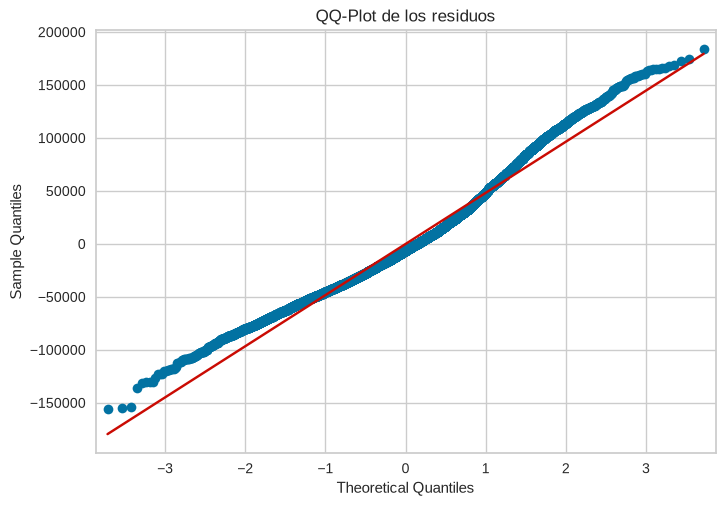

In [565]:
# QQ-Plot
sm.qqplot(model.resid, line='s')
plt.title("QQ-Plot de los residuos")
plt.show()

In [566]:
# Aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))

# Comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


/media/discoD/Facultad-IS/4to año/Fundamentos de la Ciencia de Datos (copia)/TPE/ciencia-datos-tpe/venv_tpe/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 10001.
  res = hypotest_fun_out(*samples, **kwds)


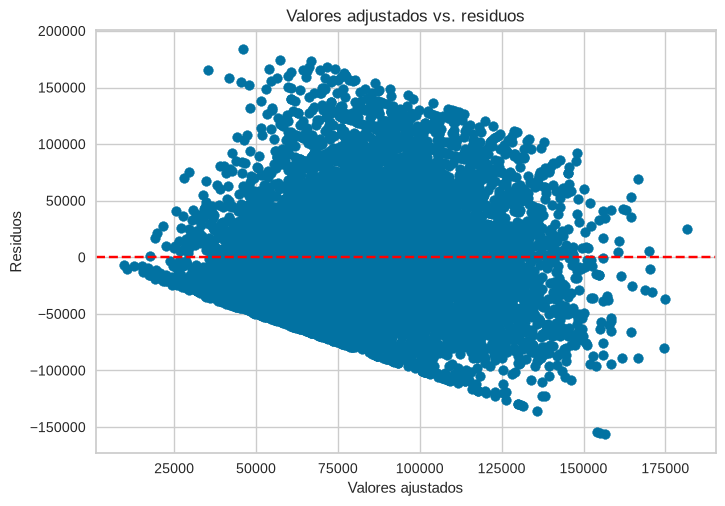

In [567]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

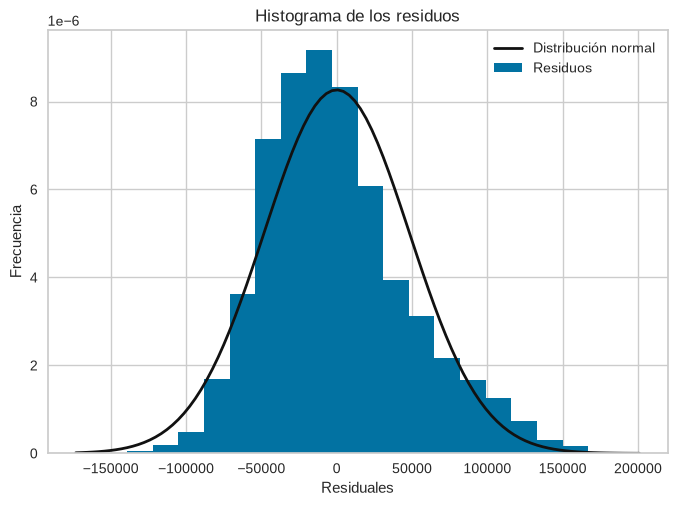

In [568]:
# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)

# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)

# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()

Asi, podemos ver claramente mediante el QQ-plot y la forma de la distribucion normal que no estamos cumpliendo dicho supuesto de normalidad pero tampoco estamos observando un compartamiento en banda que nos otorgue linealidad y homocedasticidad de dichos residuos.

<h4><u>Están los distintos niveles de satisfacción en los distintos aspectos del trabajo actual relacionados a la consideración de un cambio de rol o de carrera

In [569]:
data = df.copy()

Tenemos que la variable que almacena la informacion sobre un posible o hecho cambio de rol / carrera esta dada por `NewRole` que es de tipo cualitativa ordinal conteniendo valores como que no lo considero, lo considero levemente, lo considero seriamente, lo realizo voluntariamente y lo realizo voluntariamente.

Vamos a tomar como verdadero que considero o realizo dicho cambio de forma voluntaria.

In [570]:
role_mapped = {
    'I have neither consider or transitioned into a new career or industry': 0,
    'I have somewhat considered changing my career and/or the industry I work in': 1,
    'I have strongly considered changing my career and/or the industry I work in': 1,
    'I have transitioned into a new career and/or industry voluntarily':1,
    'I have transitioned into a new career and/or industry involuntarily': 0
}
data['NewRole'] = data['NewRole'].map(role_mapped)

In [571]:
cols = [
    
    'JobSat', 'JobSatPoints_1', 'JobSatPoints_2', 'JobSatPoints_3',
    'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6',
    'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10',
    'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14',
    'JobSatPoints_15', 'JobSatPoints_16', 'NewRole'
]

In [572]:
data = data.dropna(subset=cols)

In [573]:
scaler = StandardScaler()

In [574]:
y = data['NewRole']

In [575]:
data_scaled = pd.DataFrame(scaler.fit_transform(data[cols].drop(columns=['NewRole'])), columns=data[cols].drop(columns=['NewRole']).columns.to_list(), index=data.index)

In [576]:
import statsmodels.api as sm
X = data_scaled
X = sm.add_constant(X)  # Agregar constante para el intercepto

In [577]:
model = sm.Logit(y, X).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.655131
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                NewRole   No. Observations:                19591
Model:                          Logit   Df Residuals:                    19575
Method:                           MLE   Df Model:                           15
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                 0.05435
Time:                        13:39:36   Log-Likelihood:                -12835.
converged:                       True   LL-Null:                       -13572.
Covariance Type:            nonrobust   LLR p-value:                1.057e-305
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0658      0.015      4.427      0.000       0.037       0.095
JobSat        